# NearMiss — Predicting Risky Vehicle Encounters and Future Vehicle Trajectories
**CSE3141 · Predictive Analytics · Manipal University Jaipur**

## 1. Introduction
Predictive analytics uses historical observations to estimate unseen outcomes. NGSIM records highway vehicle trajectories at approximately 10 Hz. A following interaction involves a follower and its recorded same-lane leader. **Time to collision (TTC)** is clear longitudinal gap divided by positive closing speed under constant-velocity assumptions; it is not a guaranteed collision time.

**Stage 1:** binary Logistic Regression predicts whether a currently noncritical, continuously observed following pair enters a project-defined low-TTC condition in the next three seconds. These are surrogate labels, not verified crashes.

**Stage 2:** only after Stage 1 passes its integrity/evaluation checks, Gaussian GLMs with identity links predict one-second future lateral/longitudinal displacement, reconstructing X/Y coordinates.

The course topics are collection, cleaning, descriptive statistics, EDA, feature engineering/selection, chronological validation, regularization, classification metrics and generalized linear regression. No application, simulator or live monitoring is built. All Python logic is visible in this notebook.

In [1]:
from pathlib import Path
import sys, json, time, hashlib, platform, warnings, importlib.metadata as package_metadata
import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, brier_score_loss)
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
assert (ROOT/'NearMiss_Complete_Predictive_Analytics.ipynb').exists(), 'Launch at repository root.'
RAW = ROOT/'data/raw'
RAW.mkdir(parents=True, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.figsize': (10,4), 'figure.dpi': 110})
pd.set_option('display.max_columns', 16)
warnings.filterwarnings('error', category=ConvergenceWarning)
thread_limit = threadpool_limits(limits=1)
versions = {p: package_metadata.version(p) for p in
    ['pandas','numpy','matplotlib','seaborn','scikit-learn','scipy','requests',
     'statsmodels','nbformat','nbclient','ipykernel','jupyterlab','threadpoolctl']}
print('Python:', platform.python_version())
display(pd.Series(versions, name='version'))
def showplot():
    """Lay out the current research figure and display it in notebook outputs."""
    plt.tight_layout()
    plt.show()

Python: 3.13.9


pandas            2.3.3
numpy             2.3.5
matplotlib       3.10.6
seaborn          0.13.2
scikit-learn      1.7.2
scipy            1.16.3
requests         2.32.5
statsmodels      0.14.5
nbformat         5.10.4
nbclient         0.10.2
ipykernel        6.31.0
jupyterlab        4.4.7
threadpoolctl     3.5.0
Name: version, dtype: object

## 2. Official data collection and schema
Source: [USDOT NGSIM catalog 8ect-6jqj](https://data.transportation.gov/d/8ect-6jqj).
The [official data dictionary](https://data.transportation.gov/api/views/8ect-6jqj/files/ddb2c29d-2ef4-4b67-94ea-b55169229bd9?download=true&filename=1-+US+101+Metadata+Documentation.pdf)
defines Local_X/Local_Y as **front-center** coordinates (feet), v_Length in feet,
v_Vel in feet/s, v_Acc in feet/s² and Global_Time in epoch milliseconds.
The live catalog column descriptions are inspected below rather than assuming names.

Vehicle IDs repeat across recording periods. The recording origin
`Global_Time − 100 × Frame_ID` identifies a source recording and is audited before
choosing data. We download the **entire earliest US-101 recording**, including all
vehicles and frames, rather than an arbitrary API page. The source recording is
about 16 minutes including its tracked boundaries. For manageable execution, one
complete recording is used with purged chronological blocks; this limits claims
about independent-day generalization.

In [2]:
CATALOG = 'https://data.transportation.gov/api/views/8ect-6jqj.json'
API = 'https://data.transportation.gov/resource/8ect-6jqj'
CSV_EXPORT = 'https://data.transportation.gov/api/v3/views/8ect-6jqj/export.csv?accessType=DOWNLOAD'
client = requests.Session()
retry = Retry(total=5, backoff_factor=2, status_forcelist=[429,500,502,503,504],
              allowed_methods=['GET'], respect_retry_after_header=True)
client.mount('https://', HTTPAdapter(max_retries=retry))
def request_json(url, params=None):
    """Fetch official JSON with retries, timeouts and malformed-response checks."""
    response = client.get(url, params=params, timeout=(20,240))
    response.raise_for_status()
    value = response.json()
    if not isinstance(value, (list,dict)):
        raise ValueError('Unexpected API response type.')
    return value

try:
    catalog = request_json(CATALOG)
    (RAW/'catalog.json').write_text(json.dumps(catalog, indent=2), encoding='utf-8')
except (requests.RequestException, ValueError) as exc:
    if not (RAW/'catalog.json').exists():
        raise RuntimeError('Official catalog unavailable; retry later. '+str(exc)) from exc
    print('Network unavailable; using cached official catalog:', exc)
    catalog = json.loads((RAW/'catalog.json').read_text(encoding='utf-8'))
schema = pd.DataFrame([{'field': c.get('fieldName'), 'type': c.get('dataTypeName'),
                       'description': c.get('description')} for c in catalog['columns']])
display(schema)
print('Catalog:', catalog['name'])
print('Official complete CSV export (not downloaded wholesale):', CSV_EXPORT)
columns = ['vehicle_id','frame_id','global_time','local_x','local_y','v_length',
           'v_width','v_vel','v_acc','lane_id','preceding','following','space_headway','location']
assert set(columns).issubset(set(schema.field))
period_query = {'$select': 'global_time-frame_id*100 as origin,count(*) as n,min(global_time) as first,max(global_time) as last',
                '$where': "location='us-101'", '$group':'origin', '$order':'origin', '$limit':100}
period_path = RAW/'recording_periods.json'
if period_path.exists():
    period_records = json.loads(period_path.read_text())
else:
    period_records = request_json(API+'.json', period_query)
    period_path.write_text(json.dumps(period_records, indent=2))
periods = pd.DataFrame(period_records).astype('int64')
display(periods)
assert len(periods) >= 1
chosen = periods.sort_values('origin').iloc[0]
ORIGIN, EXPECTED = int(chosen.origin), int(chosen.n)
print('Chosen full recording origin:', ORIGIN, 'Expected source rows:', EXPECTED)

,field,type,description
0,vehicle_id,number,Vehicle identification number (ascending by ti...
1,frame_id,number,Frame Identification number (ascending by sta...
2,total_frames,number,Total number of frames in which the vehicle a...
3,global_time,number,"Elapsed time in milliseconds since Jan 1, 1970."
4,local_x,number,Lateral (X) coordinate of the front center of ...
5,local_y,number,Longitudinal (Y) coordinate of the front cente...
6,global_x,number,X Coordinate of the front center of the vehicl...
7,global_y,number,Y Coordinate of the front center of the vehicl...
8,v_length,number,Length of vehicle in feet
9,v_width,number,Width of vehicle in feet


Catalog: Next Generation Simulation (NGSIM) Vehicle Trajectories and Supporting Data
Official complete CSV export (not downloaded wholesale): https://data.transportation.gov/api/v3/views/8ect-6jqj/export.csv?accessType=DOWNLOAD


,origin,n,first,last
0,1118846978900,1180598,1118846979700,1118847932500
1,1118847842000,2107095,1118847843000,1118848842000
2,1118848757000,1515240,1118848757500,1118849752200


Chosen full recording origin: 1118846978900 Expected source rows: 1180598


In [3]:
def download_recording():
    """Download every ordered page of the selected recording; count and hash cache.

    No vehicle or frame subsampling is used. A cached local file must have a
    matching manifest and hash. Pagination ordering includes the stable API row ID.
    """
    path = RAW/'us101_complete_recording.csv'
    manifest_path = RAW/'download_manifest.json'
    def digest(file):
        with file.open('rb') as stream:
            return hashlib.file_digest(stream, 'sha256').hexdigest()
    if path.exists() and manifest_path.exists():
        manifest = json.loads(manifest_path.read_text())
        if manifest['origin'] == ORIGIN and manifest['source_rows'] == EXPECTED:
            assert digest(path) == manifest['sha256'], 'Cached data checksum mismatch.'
            print('Reusing verified cache:', path.name)
            return path
    # A manually downloaded exact filtered CSV is supported when the API is unavailable.
    # It must match the selected origin and expected total after parsing below.
    if path.exists() and not manifest_path.exists():
        local = pd.read_csv(path)
        assert set(columns).issubset(local.columns)
        assert len(local) == EXPECTED
        assert (local.global_time-local.frame_id*100 == ORIGIN).all()
        manifest_path.write_text(json.dumps(dict(origin=ORIGIN, source_rows=len(local),
            sha256=digest(path), provenance='User-supplied official filtered CSV'), indent=2))
        print('Validated local-file fallback.')
        return path
    partial = path.with_suffix('.partial')
    total, page_size = 0, 10000
    try:
        from concurrent.futures import ThreadPoolExecutor
        from io import StringIO
        page_dir = RAW/f'pages_{ORIGIN}'
        page_dir.mkdir(exist_ok=True)
        def fetch_page(offset):
            """Retry complete response-body reads and cache each verified API page."""
            cached = page_dir/f'{offset:08d}.csv'
            required = min(page_size, EXPECTED-offset)
            if cached.exists():
                page = pd.read_csv(cached)
                if len(page) == required and set(page.columns) == set(columns):
                    return cached
            params = {'$select': ','.join(columns),
                '$where': f"location='us-101' AND global_time-frame_id*100={ORIGIN}",
                '$order':'global_time,vehicle_id,frame_id,:id', '$limit':page_size, '$offset':offset}
            for attempt in range(5):
                try:
                    response = client.get(API+'.csv', params=params, timeout=(20,240))
                    response.raise_for_status()
                    page = pd.read_csv(StringIO(response.text))
                    assert set(page.columns) == set(columns), 'Malformed page/schema.'
                    assert len(page) == required, 'Incomplete API page.'
                    assert (page.global_time-page.frame_id*100 == ORIGIN).all()
                    page.to_csv(cached,index=False)
                    return cached
                except (requests.RequestException, ValueError, AssertionError) as error:
                    if attempt == 4:
                        raise RuntimeError(f'Page {offset} failed after retries: {error}') from error
                    time.sleep(min(2**attempt,16))
        offsets = list(range(0, EXPECTED, page_size))
        # Four bounded requests keep this complete-interval download practical.
        # Responses are concatenated in deterministic pagination order.
        with ThreadPoolExecutor(max_workers=4) as executor:
            for offset, cached in zip(offsets, executor.map(fetch_page, offsets)):
                page = pd.read_csv(cached)
                page.to_csv(partial, mode='w' if offset == 0 else 'a', header=offset == 0, index=False)
                total += len(page)
                if offset % 100000 == 0 or total == EXPECTED:
                    print(f'Downloaded {total:,}/{EXPECTED:,} vehicle observations', flush=True)
        assert total == EXPECTED
        partial.replace(path)
        manifest_path.write_text(json.dumps(dict(origin=ORIGIN, source_rows=total,
            sha256=digest(path), query=period_query, source=API), indent=2))
        return path
    except Exception as exc:
        raise RuntimeError('Official download failed: '+str(exc)+
            '. Rerun to retry, or export this complete origin-filtered recording from '+
            API+'.csv and save data/raw/us101_complete_recording.csv. Do not substitute synthetic records.') from exc

data_path = download_recording()
raw = pd.read_csv(data_path)
print('Shape:', raw.shape, 'Vehicle IDs:', raw.vehicle_id.nunique())
print('Recording range UTC:', pd.to_datetime(raw.global_time.min(), unit='ms', utc=True),
      'to', pd.to_datetime(raw.global_time.max(), unit='ms', utc=True))
display(raw.head(), raw.dtypes.to_frame('dtype'), raw.vehicle_id.drop_duplicates().to_frame('available_IDs'))
assert len(raw) == EXPECTED
assert raw.location.eq('us-101').all()
assert (raw.global_time-raw.frame_id*100).eq(ORIGIN).all()
display(raw[['local_x','local_y','v_vel','v_acc','v_length']].agg(['min','max']))

Reusing verified cache: us101_complete_recording.csv


Shape: (1180598, 14) Vehicle IDs: 2169
Recording range UTC: 2005-06-15 14:49:39.700000+00:00 to 2005-06-15 15:05:32.500000+00:00


,vehicle_id,frame_id,global_time,local_x,local_y,v_length,v_width,v_vel,v_acc,lane_id,preceding,following,space_headway,location
0,5,8,1118846979700,39.788,39.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101
1,5,9,1118846979800,39.767,43.153,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101
2,5,10,1118846979900,39.747,47.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101
3,5,11,1118846980000,39.726,51.154,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101
4,5,12,1118846980100,39.705,55.153,17.0,7.9,40.0,0.0,4,0,0,0.0,us-101


,dtype
vehicle_id,int64
frame_id,int64
global_time,int64
local_x,float64
local_y,float64
v_length,float64
v_width,float64
v_vel,float64
v_acc,float64
lane_id,int64


,available_IDs
0,5
5,2
25,13
46,8
60,14
...,...
1138136,3034
1141154,2963
1144181,3026
1145668,2990


,local_x,local_y,v_vel,v_acc,v_length
min,0.510,0.000,0.0,-11.2,4.0
max,73.475,2195.462,95.3,11.2,76.1


## 3. Data cleaning and unit conversion
**Purpose:** distinguish unusable rows from unusual driving/reconstruction.
We audit missingness, exact duplicates, contradictory observations at the same
recording/vehicle/time, identifier validity and physical ranges. All conflicting
duplicates are excluded, not arbitrarily resolved. Exact duplicates are redundant
and removed. Negative speed, nonpositive dimensions, negative longitudinal
position and nonfinite inputs are invalid. Lateral coordinates can extend beyond
the main-lane pavement and are not deleted solely for being negative.

IQR and |Z| > 3 are diagnostics, not automatic deletion. Large acceleration may
reflect braking or video-reconstruction artifacts. It is retained and documented.
Discontinuities break trajectory/pair runs rather than being interpolated.
**Every distance/speed/acceleration is converted with 1 foot = 0.3048 metre.**

,missing,fraction
vehicle_id,0.0,0.0
frame_id,0.0,0.0
global_time,0.0,0.0
local_x,0.0,0.0
local_y,0.0,0.0
v_length,0.0,0.0
v_width,0.0,0.0
v_vel,0.0,0.0
v_acc,0.0,0.0
lane_id,0.0,0.0


New nonnumeric values: 0


Exact duplicates removed: 0 Conflicting key rows quarantined: 0


Invalid measurement rows: 0


,count
raw_rows,1180598
exact_duplicates,0
conflicting_key_rows,0
invalid_measurements,0
clean_rows,1180598
noninitial_irregular_steps,0
speed_above_55_mps_retained,0
abs_acc_above_12_mps2_retained,0


,IQR_flag_fraction,abs_Z_gt3_fraction
x,0.000000,0.000000
y,0.000000,0.000000
speed,0.025164,0.000268
acc,0.168217,0.000000
length,0.022038,0.014577


before                                                after_SI  \
            local_x       local_y         v_vel         v_acc             x   
count  1.180598e+06  1.180598e+06  1.180598e+06  1.180598e+06  1.180598e+06   
mean   2.951850e+01  9.830088e+02  3.749641e+01  3.290519e-01  8.997239e+00   
std    1.666183e+01  5.946291e+02  1.487594e+01  5.045285e+00  5.078526e+00   
min    5.100000e-01  0.000000e+00  0.000000e+00 -1.120000e+01  1.554480e-01   
25%    1.733800e+01  4.710955e+02  2.990000e+01 -1.480000e+00  5.284622e+00   
50%    2.964500e+01  9.321150e+02  3.925000e+01  0.000000e+00  9.035796e+00   
75%    4.190600e+01  1.466302e+03  4.737000e+01  2.380000e+00  1.277295e+01   
max    7.347500e+01  2.195462e+03  9.530000e+01  1.120000e+01  2.239518e+01   

                                                               
                  y         speed           acc        length  
count  1.180598e+06  1.180598e+06  1.180598e+06  1.180598e+06  
mean   2.996211e+02  1.142891e+01  1.002950e-01  4.496373e+00  
std    1.812429e+02  4.534187e+00  1.537803e+00  1.559558e+00  
min    0.000000e+00  0.000000e+00 -3.413760e+00  1.219200e+00  
25%    1.435899e+02  9.113520e+00 -4.511040e-01  3.810000e+00  
50%    2.841087e+02  1.196340e+01  0.000000e+00  4.419600e+00  
75%    4.469289e+02  1.443838e+01  7.254240e-01  5.029200e+00  
max    6.691768e+02  2.904744e+01  3.413760e+00  2.319528e+01

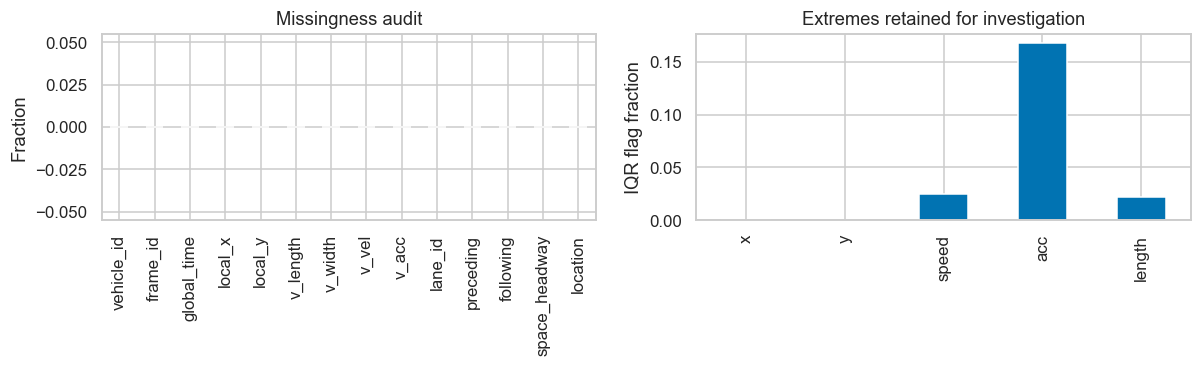

**Observation → interpretation → decision:** 1,180,598 valid observations remain. The table separates missing/conflicting records from statistical extremes. No learned outlier threshold or imputer has used the later evaluation outcomes. Signed acceleration is retained; gaps start new runs so historical/future windows cannot bridge missing data.

In [4]:
missing = raw.isna().agg(['sum','mean']).T.rename(columns={'sum':'missing','mean':'fraction'})
display(missing)
numeric_columns = [c for c in columns if c != 'location']
df = raw.copy()
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors='coerce')
print('New nonnumeric values:', int((df[numeric_columns].isna() & raw[numeric_columns].notna()).sum().sum()))
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates()
key = ['vehicle_id','global_time']
conflicting = df.duplicated(key, keep=False)
print('Exact duplicates removed:', exact_duplicates, 'Conflicting key rows quarantined:', int(conflicting.sum()))
df = df.loc[~conflicting].copy()
invalid = (~np.isfinite(df[numeric_columns]).all(axis=1) |
    (df.vehicle_id <= 0) | (df.frame_id < 0) | (df.lane_id <= 0) |
    (df.preceding < 0) | (df.following < 0) |
    (df.v_length <= 0) | (df.v_width <= 0) | (df.v_vel < 0) | (df.local_y < 0))
integer_fields = ['vehicle_id','frame_id','global_time','lane_id','preceding','following']
invalid |= (df[integer_fields] % 1 != 0).any(axis=1)
print('Invalid measurement rows:', int(invalid.sum()))
clean = df.loc[~invalid].copy()
clean[integer_fields] = clean[integer_fields].astype('int64')
for old, new in [('local_x','x'),('local_y','y'),('v_vel','speed'),('v_acc','acc'),
                 ('v_length','length'),('v_width','width'),('space_headway','headway')]:
    clean[new] = clean[old]*.3048
clean['recording'] = ORIGIN
clean['t'] = (clean.global_time-ORIGIN)/1000
clean = clean.sort_values(['vehicle_id','global_time']).reset_index(drop=True)
dt = clean.groupby('vehicle_id').global_time.diff()
clean['trajectory_run'] = ((dt != 100) | clean.vehicle_id.ne(clean.vehicle_id.shift())).cumsum()
quality_audit = pd.Series({'raw_rows':len(raw), 'exact_duplicates':exact_duplicates,
    'conflicting_key_rows':int(conflicting.sum()), 'invalid_measurements':int(invalid.sum()),
    'clean_rows':len(clean), 'noninitial_irregular_steps':int((dt.notna() & dt.ne(100)).sum()),
    'speed_above_55_mps_retained':int((clean.speed > 55).sum()),
    'abs_acc_above_12_mps2_retained':int((clean.acc.abs() > 12).sum())})
display(quality_audit.to_frame('count'))
measurements = clean[['x','y','speed','acc','length']]
q1, q3 = measurements.quantile(.25), measurements.quantile(.75)
iqr_flags = ((measurements < q1-1.5*(q3-q1)) | (measurements > q3+1.5*(q3-q1))).mean()
z_flags = ((measurements-measurements.mean())/measurements.std()).abs().gt(3).mean()
display(pd.DataFrame({'IQR_flag_fraction':iqr_flags, 'abs_Z_gt3_fraction':z_flags}))
display(pd.concat({'before':df[['local_x','local_y','v_vel','v_acc']].describe(),
                   'after_SI':measurements.describe()}, axis=1))
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
missing.fraction.plot.bar(ax=axes[0]); axes[0].set(title='Missingness audit', ylabel='Fraction')
iqr_flags.plot.bar(ax=axes[1]); axes[1].set(title='Extremes retained for investigation', ylabel='IQR flag fraction')
showplot()
display(Markdown(f'**Observation → interpretation → decision:** {len(clean):,} valid observations remain. '
    'The table separates missing/conflicting records from statistical extremes. No learned '
    'outlier threshold or imputer has used the later evaluation outcomes. Signed acceleration '
    'is retained; gaps start new runs so historical/future windows cannot bridge missing data.'))

## 4. Exploratory data analysis
**Purpose:** understand movement scales, imbalance in observation duration, and
relationships before constructing labels. Behavioral EDA uses the **first 60% of
the time range** only. Chronological boundaries are predefined, not selected from
model scores. Sampling in plots is only for rendering; extraction uses all cleaned
observations. Detailed future-period distributions are reserved for evaluation.

,x,y,speed,acc,headway
mean,8.941553,286.175904,12.838632,0.151875,25.079030
median,8.994038,269.382850,12.679680,0.000000,22.140672
var,26.350290,31671.501353,16.997177,2.399085,239.642018
std,5.133253,177.964888,4.122763,1.548898,15.480375
min,0.155448,0.000000,0.000000,-3.413760,0.000000
max,22.395180,669.176818,29.047440,3.413760,237.052104


,x,y,speed,acc,headway
0.25,5.163160,132.776976,10.655808,-0.414528,15.925800
0.50,8.994038,269.382850,12.679680,0.000000,22.140672
0.75,12.761824,424.019320,15.569184,0.844296,31.211520


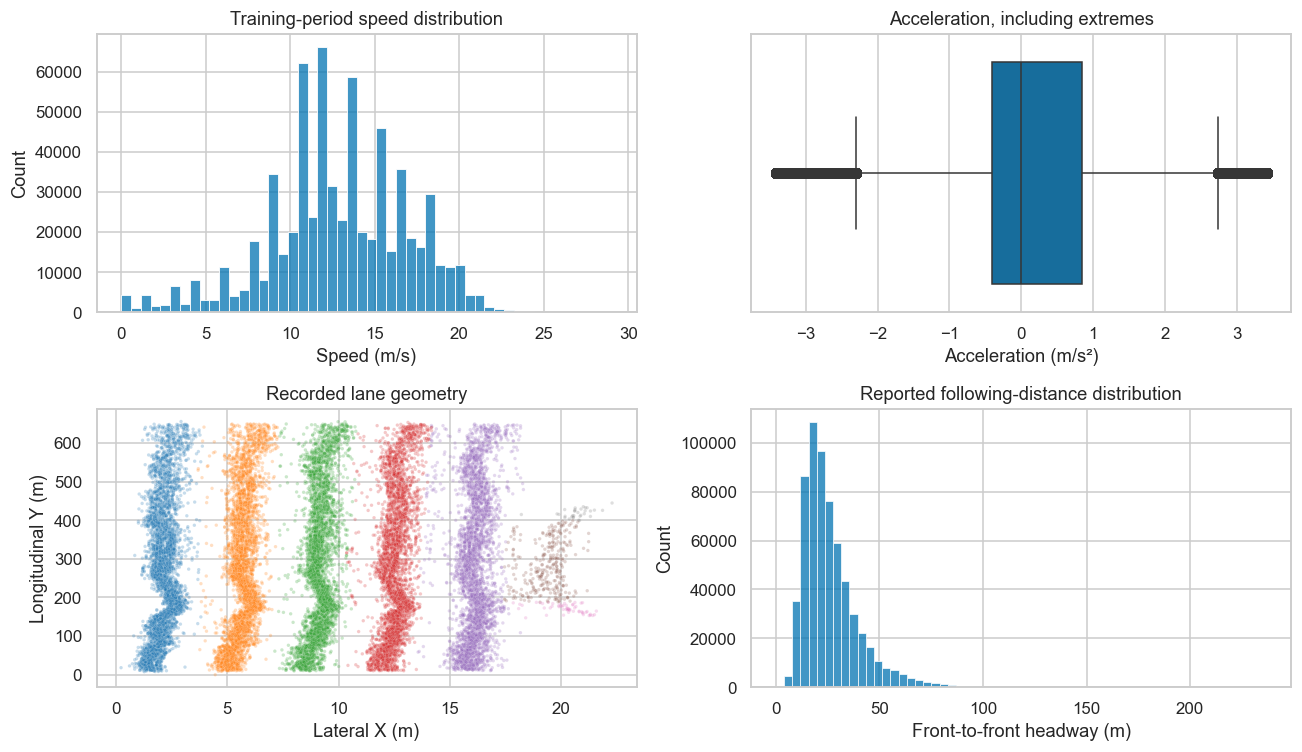

**Observation:** speeds and accelerations have different scales, lane geometry appears in X/Y, and headway is strongly variable. **Interpretation:** front-to-front headway is not clear bumper gap; coordinates and leader length must be joined first. **Decision:** standardize training features and retain both kinematic state and variability.

In [5]:
TMIN, TMAX = int(clean.global_time.min()), int(clean.global_time.max())
SPAN = TMAX-TMIN
B1, B2 = int(TMIN+.60*SPAN), int(TMIN+.80*SPAN)
def assign_partition(start_time, end_time):
    """Assign full history-to-target support to one chronological block.

    Five seconds on either side of each boundary are embargoed. A sample must
    fit wholly inside its block; no past/future support crosses a boundary.
    """
    start_time, end_time = np.asarray(start_time), np.asarray(end_time)
    return np.select([(start_time >= TMIN) & (end_time < B1-5000),
                      (start_time > B1+5000) & (end_time < B2-5000),
                      (start_time > B2+5000) & (end_time <= TMAX)],
                      ['train','validation','test'], default='excluded')

eda = clean[clean.global_time < B1-5000]
display(eda[['x','y','speed','acc','headway']].agg(['mean','median','var','std','min','max']))
display(eda[['x','y','speed','acc','headway']].quantile([.25,.5,.75]))
fig, axes = plt.subplots(2,2,figsize=(12,7))
sns.histplot(eda.speed, bins=50, ax=axes[0,0]); axes[0,0].set(xlabel='Speed (m/s)', title='Training-period speed distribution')
sns.boxplot(x=eda.acc, ax=axes[0,1]); axes[0,1].set(xlabel='Acceleration (m/s²)', title='Acceleration, including extremes')
plot_rows = eda.sample(min(20000,len(eda)), random_state=SEED)
sns.scatterplot(data=plot_rows, x='x', y='y', hue='lane_id', palette='tab10', s=5, alpha=.25, legend=False, ax=axes[1,0])
axes[1,0].set(xlabel='Lateral X (m)', ylabel='Longitudinal Y (m)', title='Recorded lane geometry')
sns.histplot(eda.loc[eda.headway > 0,'headway'], bins=60, ax=axes[1,1])
axes[1,1].set(xlabel='Front-to-front headway (m)', title='Reported following-distance distribution')
showplot()
display(Markdown('**Observation:** speeds and accelerations have different scales, lane geometry '
    'appears in X/Y, and headway is strongly variable. **Interpretation:** front-to-front headway '
    'is not clear bumper gap; coordinates and leader length must be joined first. '
    '**Decision:** standardize training features and retain both kinematic state and variability.'))

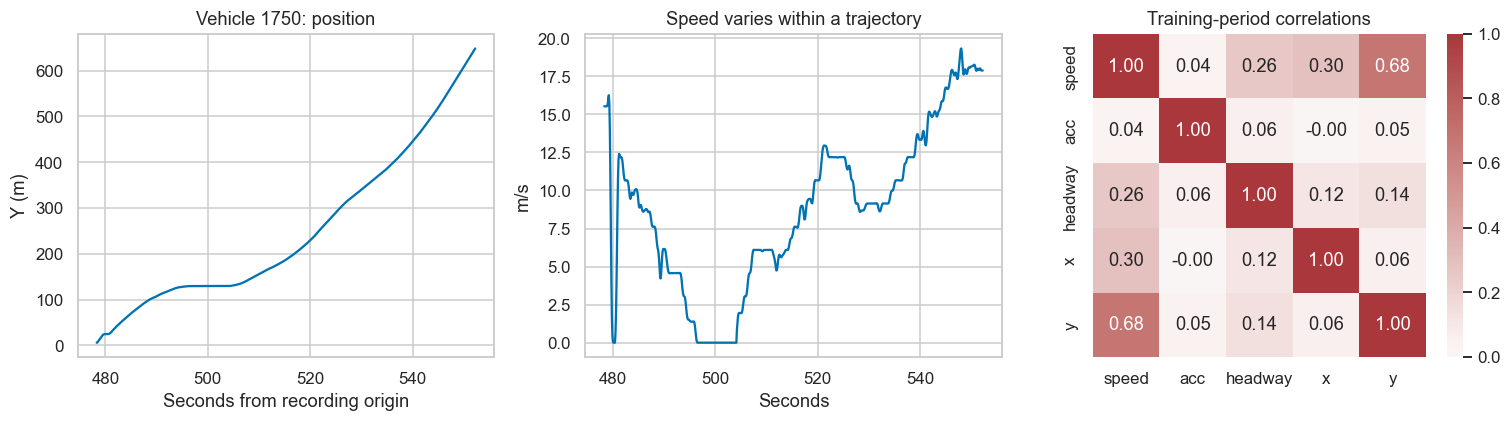

**Observation → interpretation:** the time trace exposes acceleration/deceleration that a single snapshot cannot summarize; correlations identify potentially redundant measurements. **Decision:** compare current-state features against trailing-history summaries using an ablation, rather than assuming that more features necessarily help.

In [6]:
chosen_vehicle = int(eda.groupby('vehicle_id').size().sort_values(ascending=False).index[0])
example = eda[eda.vehicle_id == chosen_vehicle]
fig, axes = plt.subplots(1,3,figsize=(14,4))
axes[0].plot(example.t, example.y); axes[0].set(xlabel='Seconds from recording origin',ylabel='Y (m)',title=f'Vehicle {chosen_vehicle}: position')
axes[1].plot(example.t, example.speed); axes[1].set(xlabel='Seconds',ylabel='m/s',title='Speed varies within a trajectory')
sns.heatmap(eda[['speed','acc','headway','x','y']].corr(), annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[2])
axes[2].set_title('Training-period correlations')
showplot()
display(Markdown('**Observation → interpretation:** the time trace exposes acceleration/deceleration '
    'that a single snapshot cannot summarize; correlations identify potentially redundant measurements. '
    '**Decision:** compare current-state features against trailing-history summaries using an ablation, '
    'rather than assuming that more features necessarily help.'))

# Stage 1 — Future close-following risk classification
## 5. Validating same-lane following pairs
**Purpose:** match the recorded Preceding ID to a leader at exactly the same
recording and timestamp. No nearest-neighbor inference is used.

Both positions are front-center references, so clear bumper gap is
**leader Y − leader length − follower Y**, not center distance minus both lengths.
Require a positive gap, a leader ahead, equal lane, different IDs and reciprocal
Following reference. Invalid/missing links are excluded and counted. A recorded
pair is split into a new encounter whenever time is discontinuous, lane changes,
or leader identity changes. This prevents treating a replacement leader as the
same future interaction.

In [7]:
def identify_pairs(vehicles):
    """Join same-timestamp recorded leader/follower IDs and validate geometry.

    Input is one cleaned recording in SI units. Output contains conservative,
    reciprocal same-lane pairs and an exclusion audit; missing links are not safe.
    """
    follower = vehicles[['recording','vehicle_id','global_time','lane_id','preceding',
                         'y','speed','acc','headway']].copy()
    leader = vehicles[['recording','vehicle_id','global_time','lane_id','y','speed',
                       'acc','length','following']].rename(columns={
        'vehicle_id':'leader_id','lane_id':'leader_lane','y':'leader_y',
        'speed':'leader_speed','acc':'leader_acc','length':'leader_length',
        'following':'leader_following'})
    joined = follower.merge(leader, how='left',
        left_on=['recording','preceding','global_time'],
        right_on=['recording','leader_id','global_time'], validate='many_to_one')
    joined['gap'] = joined.leader_y-joined.leader_length-joined.y
    remaining = pd.Series(True,index=joined.index)
    audit = {}
    checks = [
        ('no_recorded_leader', joined.preceding.le(0)),
        ('leader_missing_at_timestamp', joined.leader_id.isna()),
        ('self_reference', joined.preceding.eq(joined.vehicle_id)),
        ('different_lane', joined.lane_id.ne(joined.leader_lane)),
        ('leader_not_ahead', joined.leader_y.le(joined.y)),
        ('nonpositive_clear_gap', joined.gap.le(0)),
        ('nonreciprocal_following_reference', joined.leader_following.ne(joined.vehicle_id))]
    for reason, bad in checks:
        audit[reason] = int((remaining & bad).sum())
        remaining &= ~bad
    pairs = joined.loc[remaining].sort_values(['vehicle_id','global_time']).reset_index(drop=True)
    boundary = (pairs.vehicle_id.ne(pairs.vehicle_id.shift()) |
        pairs.preceding.ne(pairs.preceding.shift()) |
        pairs.lane_id.ne(pairs.lane_id.shift()) |
        pairs.global_time.diff().ne(100))
    pairs['encounter'] = boundary.cumsum().astype(int)
    audit['valid_pair_observations'] = len(pairs)
    assert sum(v for k,v in audit.items() if k != 'valid_pair_observations')+len(pairs) == len(vehicles)
    return pairs, pd.Series(audit, name='observations')

pairs, pair_audit = identify_pairs(clean)
display(pair_audit.to_frame())
assert (pairs.gap > 0).all()
assert pairs.lane_id.eq(pairs.leader_lane).all()
assert pairs.preceding.eq(pairs.leader_id).all()
assert pairs.leader_following.eq(pairs.vehicle_id).all()
print('Unique encounters:', pairs.encounter.nunique())
headway_residual = pairs.headway-(pairs.leader_y-pairs.y)
display(headway_residual.describe().to_frame('reported minus coordinate front-spacing (m)'))
display(Markdown(f'**Observed:** {len(pairs):,} valid reciprocal pair observations remain. '
    'The front-spacing residual audits agreement with the source headway; it is not '
    'substituted for clear gap. Exclusions define a conservative same-lane study population '
    'and can omit lane-change/complex encounters, limiting external validity.'))

,observations
no_recorded_leader,59381
leader_missing_at_timestamp,0
self_reference,0
different_lane,0
leader_not_ahead,1
nonpositive_clear_gap,1909
nonreciprocal_following_reference,0
valid_pair_observations,1119307


Unique encounters: 5047


,reported minus coordinate front-spacing (m)
count,1.119307e+06
mean,7.410136e-06
std,8.874969e-04
min,-1.524000e-03
25%,-6.096000e-04
50%,0.000000e+00
75%,9.144000e-04
max,1.524000e-03


**Observed:** 1,119,307 valid reciprocal pair observations remain. The front-spacing residual audits agreement with the source headway; it is not substituted for clear gap. Exclusions define a conservative same-lane study population and can omit lane-change/complex encounters, limiting external validity.

## 6. Relative motion and TTC
Closing speed is follower speed minus leader speed. For positive closing speed,
TTC = gap / closing speed. Otherwise TTC is **infinite**, explicitly representing
no constant-velocity closure. To feed a finite predictor to Logistic Regression,
use inverse TTC = max(closing speed, 0)/gap. Zero inverse TTC means nonclosing;
it is not a claim that future risk is impossible.

Gap trend is calculated only from adjacent past observations of the same encounter.
Recorded speed and position derivatives can disagree because of reconstruction
noise; TTC remains a surrogate based on the supplied instantaneous speeds.

Nonclosing TTC cases: 655171


,gap,speed,leader_speed,closing,gap_change_rate,acc
count,626216.000000,626216.000000,626216.000000,626216.000000,623003.000000,626216.000000
mean,22.142025,12.535051,12.922343,-0.387291,0.387828,0.152792
std,14.540439,3.991382,4.124334,1.634983,1.663929,1.549912
min,0.002438,0.000000,0.000000,-19.921728,-28.133040,-3.413760
25%,12.639142,10.552176,10.664952,-1.399032,-0.554736,-0.414528
50%,18.618403,12.310872,12.914376,-0.252984,0.240792,0.000000
75%,27.400301,15.240000,15.709392,0.530352,1.432560,0.841248
max,229.584809,29.047440,29.047440,18.379440,44.698920,3.413760


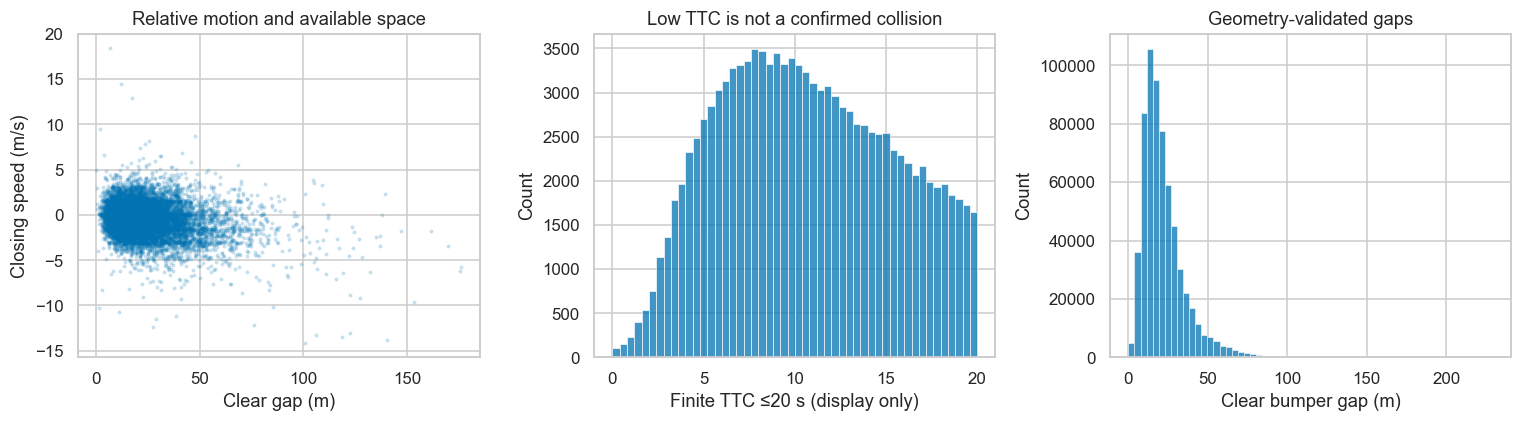

**Observation → interpretation:** identical gaps can have different closing speeds, so distance alone cannot characterize constant-velocity closure. Nonclosing states have infinite TTC and remain in the population. **Decision:** use gap, closing speed and finite inverse TTC, then ask whether history adds predictive information.

In [8]:
pairs['closing'] = pairs.speed-pairs.leader_speed
pairs['inverse_ttc'] = pairs.closing.clip(lower=0)/pairs.gap
pairs['ttc'] = np.divide(pairs.gap, pairs.closing,
    out=np.full(len(pairs), np.inf), where=pairs.closing.to_numpy() > 0)
g = pairs.groupby('encounter', sort=False)
pairs['gap_change_rate'] = g.gap.diff()/.1
pairs['braking'] = pairs.acc.lt(0).astype(float)
assert np.isfinite(pairs.inverse_ttc).all()
assert pairs.loc[pairs.closing <= 0,'ttc'].eq(np.inf).all()
assert np.allclose(pairs.loc[pairs.closing > 0,'ttc']*pairs.loc[pairs.closing > 0,'closing'],
                   pairs.loc[pairs.closing > 0,'gap'])
print('Nonclosing TTC cases:', int((pairs.closing <= 0).sum()))
train_pair_rows = pairs[pairs.global_time < B1-5000]
display(train_pair_rows[['gap','speed','leader_speed','closing','gap_change_rate','acc']].describe())
fig, axes = plt.subplots(1,3,figsize=(14,4))
p = train_pair_rows.sample(min(15000,len(train_pair_rows)),random_state=SEED)
axes[0].scatter(p.gap,p.closing,s=3,alpha=.15); axes[0].set(xlabel='Clear gap (m)',ylabel='Closing speed (m/s)',title='Relative motion and available space')
finite = train_pair_rows.loc[np.isfinite(train_pair_rows.ttc),'ttc']
sns.histplot(finite[finite <= 20],bins=50,ax=axes[1])
axes[1].set(xlabel='Finite TTC ≤20 s (display only)',title='Low TTC is not a confirmed collision')
sns.histplot(train_pair_rows.gap,bins=60,ax=axes[2]); axes[2].set(xlabel='Clear bumper gap (m)',title='Geometry-validated gaps')
showplot()
display(Markdown('**Observation → interpretation:** identical gaps can have different closing speeds, '
    'so distance alone cannot characterize constant-velocity closure. Nonclosing states have '
    'infinite TTC and remain in the population. **Decision:** use gap, closing speed and finite '
    'inverse TTC, then ask whether history adds predictive information.'))

## 7. Future onset label and censoring policy
Primary condition: **any TTC ≤ 2 seconds in (t, t+3 seconds]** for the same
continuously observed pair. The 2-second threshold is a **project-defined
experimental cutoff**, not a universally validated crash boundary. FHWA's
[Surrogate Safety Assessment Model](https://www.fhwa.dot.gov/publications/research/safety/08051/)
uses TTC as a surrogate; our cutoff and onset protocol are separately specified.

Only currently noncritical anchors (TTC > 2 s, including nonclosing states) are
eligible. Require all 30 future 0.1-second observations of the same pair. Separation,
lane change, missing records or recording end censor the sample **even if some
earlier future observations look safe or critical**. This complete-horizon policy
is conservative and may bias results toward stable following interactions; missing
future data is never labeled safe.

## 8. Two-second historical feature windows
Use t−2 through t (21 observations) for trailing gap/speed variability, gap trend,
relative-speed change, mean follower/leader acceleration and braking fraction.
Only t+0.1 through t+3 creates the label. Anchor sampling every second reduces
density, while nearby samples still overlap **within** a partition. Entire encounters
must fit a single chronological block with ±5-second boundary embargoes.

,sequential_exclusion_count
off_one_second_anchor_grid,1007361
insufficient_two_second_history,8961
incomplete_future_or_pair_changed,11138
currently_critical,241
encounter_crosses_split_or_embargo,14991
eligible_samples,76615


target,0,1
partition,,
test,15887,443
train,47489,275
validation,12430,91


Real-observation history/label alignment checks passed.


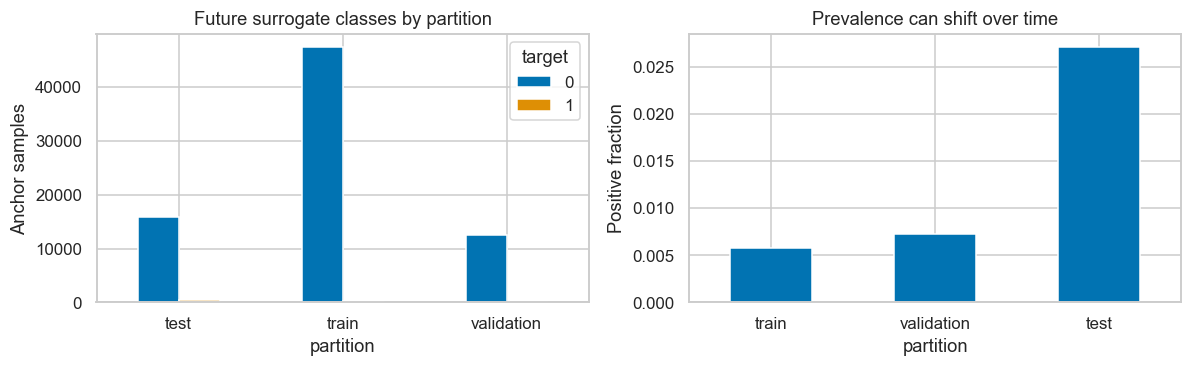

**Observation → interpretation:** the class table quantifies actual onset prevalence and censoring; a negative means a fully observed noncritical horizon, not a missing horizon. **Decision:** emphasize precision–recall, retain all eligible negatives, and fit scaling only on training.

In [9]:
def engineer_risk_samples(pair_rows, threshold=2., history_steps=20, horizon_steps=30):
    """Build past-only features and complete-horizon onset labels.

    pair_rows must have 100-ms contiguous encounters. Future maximum inverse TTC
    labels low TTC without converting nonclosing infinity to an arbitrary number.
    All future quantities are retained as metadata, never in predictor lists.
    """
    table = pair_rows.copy()
    group = table.groupby('encounter',sort=False)
    table['history_start'] = group.global_time.shift(history_steps)
    table['future_end'] = group.global_time.shift(-horizon_steps)
    table['gap_trend'] = (table.gap-group.gap.shift(history_steps))/(history_steps*.1)
    table['closing_change'] = (table.closing-group.closing.shift(history_steps))/(history_steps*.1)
    def trailing(column, stat):
        roll = group[column].rolling(history_steps+1,min_periods=history_steps+1)
        return getattr(roll, stat)().reset_index(level=0,drop=True).reindex(table.index)
    for column, stat, new in [('gap','std','gap_std'),('speed','std','speed_std'),
        ('acc','mean','mean_acc'),('leader_acc','mean','leader_mean_acc'),
        ('braking','mean','braking_fraction')]:
        table[new] = trailing(column,stat)
    table['future_max_inverse_ttc'] = group.inverse_ttc.transform(
        lambda s: s.shift(-1).iloc[::-1].rolling(horizon_steps,min_periods=horizon_steps).max().iloc[::-1])
    # Whole-encounter assignment prevents the same following episode crossing splits.
    bounds = group.global_time.agg(['min','max'])
    bounds['partition'] = assign_partition(bounds['min'],bounds['max'])
    table['partition'] = table.encounter.map(bounds.partition)
    audit, remaining = {}, pd.Series(True,index=table.index)
    checks = [('off_one_second_anchor_grid', table.global_time.mod(1000).ne(0)),
              ('insufficient_two_second_history', table.history_start.isna()),
              ('incomplete_future_or_pair_changed', table.future_end.isna() | table.future_max_inverse_ttc.isna()),
              ('currently_critical', table.inverse_ttc.ge(1/threshold)),
              ('encounter_crosses_split_or_embargo', table.partition.eq('excluded'))]
    for reason, bad in checks:
        audit[reason] = int((remaining & bad).sum())
        remaining &= ~bad
    samples = table.loc[remaining].copy()
    samples['target'] = samples.future_max_inverse_ttc.ge(1/threshold).astype(int)
    audit['eligible_samples'] = len(samples)
    assert sum(audit.values()) == len(table)
    return samples, pd.Series(audit,name='sequential_exclusion_count')

risk, label_audit = engineer_risk_samples(pairs)
display(label_audit.to_frame())
display(pd.crosstab(risk.partition,risk.target))
assert risk.groupby('encounter').partition.nunique().max() == 1
assert risk.history_start.lt(risk.global_time).all()
assert risk.future_end.eq(risk.global_time+3000).all()
assert risk.history_start.eq(risk.global_time-2000).all()
assert risk.inverse_ttc.lt(.5).all()
for _, row in risk.sample(min(50,len(risk)),random_state=SEED).iterrows():
    # Independently recompute labels and historical endpoints on real source pairs.
    encounter = pairs[pairs.encounter == row.encounter]
    future = encounter[(encounter.global_time > row.global_time) &
                       (encounter.global_time <= row.global_time+3000)]
    history = encounter[(encounter.global_time >= row.global_time-2000) &
                        (encounter.global_time <= row.global_time)]
    assert len(future) == 30 and len(history) == 21
    assert row.target == int((future.ttc <= 2).any())
    assert np.isclose(row.gap_trend,(history.gap.iloc[-1]-history.gap.iloc[0])/2)
print('Real-observation history/label alignment checks passed.')
fig, axes = plt.subplots(1,2,figsize=(11,3.5))
pd.crosstab(risk.partition,risk.target).plot.bar(ax=axes[0],rot=0)
axes[0].set(ylabel='Anchor samples',title='Future surrogate classes by partition')
risk.groupby('partition').target.mean().reindex(['train','validation','test']).plot.bar(ax=axes[1],rot=0)
axes[1].set(ylabel='Positive fraction',title='Prevalence can shift over time')
showplot()
display(Markdown('**Observation → interpretation:** the class table quantifies actual onset prevalence '
    'and censoring; a negative means a fully observed noncritical horizon, not a missing horizon. '
    '**Decision:** emphasize precision–recall, retain all eligible negatives, and fit scaling only on training.'))

## 9. Feature selection and interpretation
The current-state model uses **gap, closing speed and inverse TTC**. The enriched
model adds only history summaries, keeping the ablation focused. IDs, lane,
timestamp, encounter, future TTC and target are excluded. We predefine a small
interpretable feature set rather than choose features from test outcomes.
Inverse TTC is a nonlinear interaction of gap and closing speed; L2 regularization
handles their redundancy. Training correlation and standardized coefficients are
descriptive, not causal effects or independent significance tests.

## 10. Train/validation/test design
The first 60%, next 20% and final 20% of one complete source recording define
chronological blocks, with a five-second embargo on either side of boundaries.
Entire following encounters crossing a boundary are excluded. A history/forecast
support check verifies every sample lies wholly inside its assigned block.

This is **one purged predefined validation fold**, not repeated random
cross-validation or an independent-day test. Tuning uses validation, so its score
is a selection estimate. The later block is the final evaluation.

train samples: 47764 positive: 275 encounters: 1998 followers: 1323
validation samples: 12521 positive: 91 encounters: 569 followers: 358
test samples: 16330 positive: 443 encounters: 454 followers: 282
Exact temporal support and encounter separation verified.


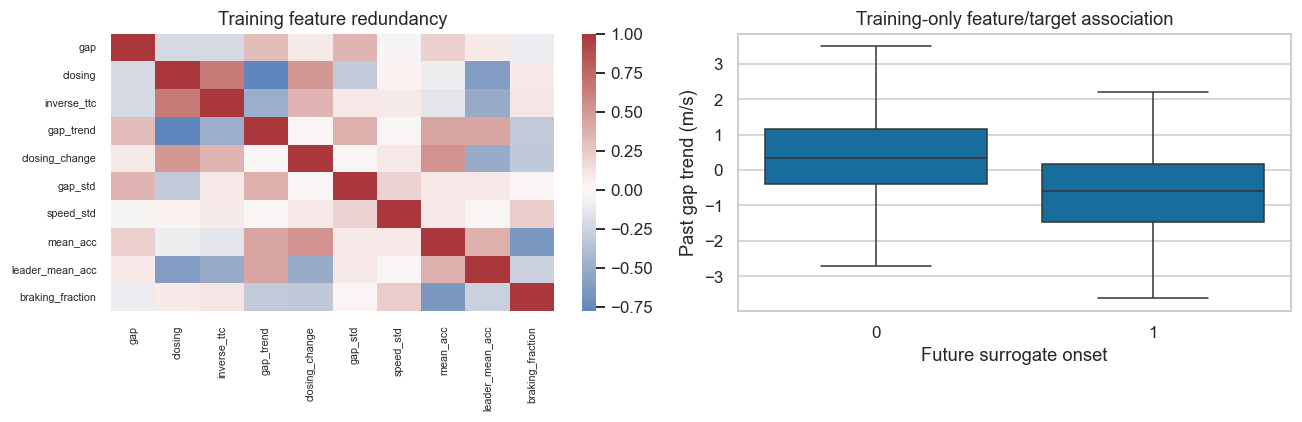

**Observation → interpretation:** training correlations expose related kinematic summaries; the target comparison asks whether recent gap change differs before onset. **Decision:** retain the predefined compact groups and assess added history by held-out ablation; do not infer causation or remove features using test scores.

In [10]:
current_features = ['gap','closing','inverse_ttc']
history_features = ['gap_trend','closing_change','gap_std','speed_std',
                    'mean_acc','leader_mean_acc','braking_fraction']
rich_features = current_features+history_features
train = risk[risk.partition == 'train'].copy()
valid = risk[risk.partition == 'validation'].copy()
test = risk[risk.partition == 'test'].copy()
for name, part in [('train',train),('validation',valid),('test',test)]:
    assert set(part.target.unique()) == {0,1}, f'{name} needs both classes.'
    assert (assign_partition(part.history_start,part.future_end) == name).all()
    print(name, 'samples:',len(part),'positive:',int(part.target.sum()),
          'encounters:',part.encounter.nunique(),'followers:',part.vehicle_id.nunique())
assert train.future_end.max() < valid.history_start.min()
assert valid.future_end.max() < test.history_start.min()
assert not set(train.encounter) & set(valid.encounter)
assert not set(train.encounter) & set(test.encounter)
assert not set(valid.encounter) & set(test.encounter)
print('Exact temporal support and encounter separation verified.')
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.heatmap(train[rich_features].corr(),cmap='vlag',center=0,ax=axes[0])
axes[0].tick_params(labelsize=7); axes[0].set_title('Training feature redundancy')
sns.boxplot(data=train,x='target',y='gap_trend',showfliers=False,ax=axes[1])
axes[1].set(xlabel='Future surrogate onset',ylabel='Past gap trend (m/s)',title='Training-only feature/target association')
showplot()
display(Markdown('**Observation → interpretation:** training correlations expose related kinematic '
    'summaries; the target comparison asks whether recent gap change differs before onset. '
    '**Decision:** retain the predefined compact groups and assess added history by held-out ablation; '
    'do not infer causation or remove features using test scores.'))

## 11. Binary Logistic Regression and validation selection
The model estimates p = sigmoid(β₀ + βᵀx), with standardized numeric features.
L2 regularization controls coefficient magnitude (larger C means less shrinkage).
A training-fit median imputer and scaler remain inside a Pipeline. A small
C ∈ {0.1, 1, 10} grid uses blocked validation **average precision**. Class balancing
is fixed in advance to emphasize rare onsets, and can affect probability calibration.

Each model's probability threshold maximizes validation F1 on a predefined grid.
A separate **current-TTC warning baseline** chooses its warning cutoff on validation
among {2.5, 3, 4, 5, 8, 10} seconds. A cutoff of two seconds would trivially warn
on none of our currently noncritical anchors; larger cutoffs make it anticipatory.
No threshold is chosen on test. Models remain fit on training only.

current selected C: {'logistic__C': 10.0} threshold: 0.97


history selected C: {'logistic__C': 0.1} threshold: 0.97


,model,C,train_AP,validation_AP
0,current,0.1,0.096187,0.104183
1,current,1.0,0.096272,0.104184
2,current,10.0,0.096273,0.104188
3,history,0.1,0.088811,0.099709
4,history,1.0,0.088807,0.099551
5,history,10.0,0.088808,0.099602


Validation-selected TTC warning cutoff: 4.0


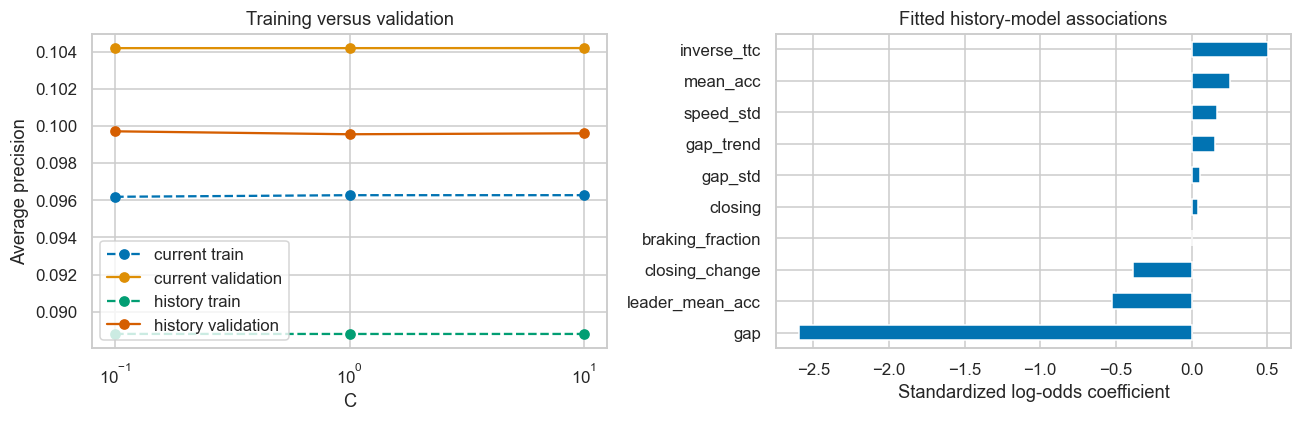

**Observation → interpretation:** the tuning table distinguishes fitting from chronological generalization. A positive standardized coefficient increases modeled log odds conditional on the other included summaries. **Decision:** freeze C, preprocessing, features and decision thresholds now; later errors are reported without retuning.

In [11]:
def logistic_pipeline():
    """Return train-fit preprocessing and regularized binary Logistic Regression."""
    return Pipeline([('imputer',SimpleImputer(strategy='median')),
        ('scale',StandardScaler()),
        ('logistic',LogisticRegression(C=1.,solver='lbfgs',class_weight='balanced',
                                      max_iter=2000,random_state=SEED))])

fold = PredefinedSplit(np.r_[np.full(len(train),-1),np.zeros(len(valid),dtype=int)])
pool = pd.concat([train,valid],ignore_index=True)
models, probability_thresholds, tuning_rows = {}, {}, []
def select_probability_threshold(y, probability):
    """Select an F1 operating point using validation predictions only."""
    grid = np.linspace(.01,.99,99)
    scores = np.array([f1_score(y,probability >= t,zero_division=0) for t in grid])
    return float(grid[np.argmax(scores)])

for name, feature_list in [('current',current_features),('history',rich_features)]:
    search = GridSearchCV(logistic_pipeline(),{'logistic__C':[.1,1.,10.]},
        scoring='average_precision',cv=fold,refit=False,n_jobs=1,error_score='raise',
        return_train_score=True)
    search.fit(pool[feature_list],pool.target)
    fitted = logistic_pipeline().set_params(**search.best_params_).fit(train[feature_list],train.target)
    models[name] = fitted
    probability_thresholds[name] = select_probability_threshold(valid.target,fitted.predict_proba(valid[feature_list])[:,1])
    for params,tr,va in zip(search.cv_results_['params'],search.cv_results_['mean_train_score'],search.cv_results_['mean_test_score']):
        tuning_rows.append(dict(model=name,C=params['logistic__C'],train_AP=tr,validation_AP=va))
    print(name,'selected C:',search.best_params_,'threshold:',probability_thresholds[name])
tuning = pd.DataFrame(tuning_rows)
display(tuning)
rule_cutoffs = [2.5,3.,4.,5.,8.,10.]
rule_f1 = [f1_score(valid.target,valid.ttc <= cutoff,zero_division=0) for cutoff in rule_cutoffs]
rule_cutoff = float(rule_cutoffs[int(np.argmax(rule_f1))])
print('Validation-selected TTC warning cutoff:',rule_cutoff)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name, block in tuning.groupby('model'):
    axes[0].plot(block.C,block.train_AP,'o--',label=name+' train')
    axes[0].plot(block.C,block.validation_AP,'o-',label=name+' validation')
axes[0].set(xscale='log',xlabel='C',ylabel='Average precision',title='Training versus validation'); axes[0].legend()
coefficients = pd.Series(models['history'].named_steps['logistic'].coef_[0],index=rich_features).sort_values()
coefficients.plot.barh(ax=axes[1]); axes[1].set(xlabel='Standardized log-odds coefficient',title='Fitted history-model associations')
showplot()
display(Markdown('**Observation → interpretation:** the tuning table distinguishes fitting from '
    'chronological generalization. A positive standardized coefficient increases modeled log odds '
    'conditional on the other included summaries. **Decision:** freeze C, preprocessing, features '
    'and decision thresholds now; later errors are reported without retuning.'))

### Training/validation-only label sensitivity
A 2-second TTC threshold is a design choice. On a **common cohort with current
TTC > 2.5 seconds**, compare future labels at 1.5, 2 and 2.5 seconds. Only training
and validation anchors participate. This diagnoses dependence on the surrogate
definition; it does not choose a favorable test label.

,TTC_cutoff,train_prevalence,validation_prevalence,validation_AP
0,1.5,0.002180,0.002480,0.071251
1,2.0,0.005408,0.006879,0.075404
2,2.5,0.011424,0.014719,0.135915


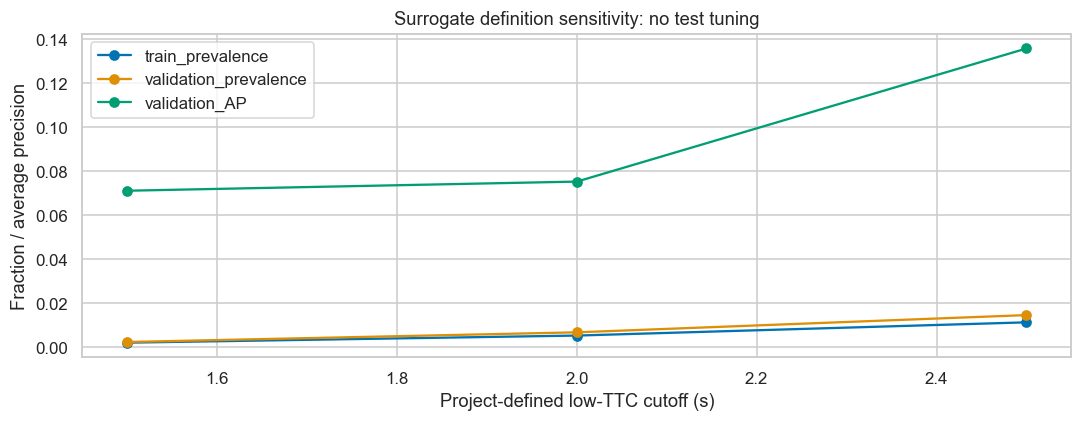

**Observation → interpretation:** changing the surrogate cutoff changes both prevalence and the prediction problem. **Decision:** keep the predeclared two-second primary label and report sensitivity instead of claiming a universal danger boundary.

In [12]:
sensitivity = []
for tau in [1.5,2.,2.5]:
    a = train[train.inverse_ttc < 1/2.5]
    b = valid[valid.inverse_ttc < 1/2.5]
    ya = a.future_max_inverse_ttc.ge(1/tau).astype(int)
    yb = b.future_max_inverse_ttc.ge(1/tau).astype(int)
    if ya.nunique() < 2 or yb.nunique() < 2:
        sensitivity.append(dict(TTC_cutoff=tau,train_prevalence=ya.mean(),validation_prevalence=yb.mean(),validation_AP=np.nan))
        continue
    fit = logistic_pipeline().set_params(logistic__C=models['history'].named_steps['logistic'].C).fit(a[rich_features],ya)
    probability = fit.predict_proba(b[rich_features])[:,1]
    sensitivity.append(dict(TTC_cutoff=tau,train_prevalence=ya.mean(),validation_prevalence=yb.mean(),
        validation_AP=average_precision_score(yb,probability)))
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity)
sensitivity.set_index('TTC_cutoff')[['train_prevalence','validation_prevalence','validation_AP']].plot(marker='o')
plt.xlabel('Project-defined low-TTC cutoff (s)'); plt.ylabel('Fraction / average precision')
plt.title('Surrogate definition sensitivity: no test tuning'); showplot()
display(Markdown('**Observation → interpretation:** changing the surrogate cutoff changes both prevalence '
    'and the prediction problem. **Decision:** keep the predeclared two-second primary label and '
    'report sensitivity instead of claiming a universal danger boundary.'))

## 12. Held-out evaluation
Precision measures how often warnings correspond to the defined future condition;
recall measures how many onsets are warned about. F1 balances them. ROC-AUC evaluates
ranking over both classes; precision–recall and average precision are more sensitive
to low prevalence. AUC for the warning rule uses its continuous inverse-TTC score,
while its precision/recall use its validation-chosen cutoff.

Brier score and reliability curves assess probability behavior. Good ranking does
not establish calibrated probabilities. Class weighting, temporal drift and
dependent windows limit interpretation; we do not calibrate on test.

,partition,model,accuracy,precision,recall,f1,roc_auc,average_precision,TN,FP,FN,TP
0,train,current,0.988108,0.146988,0.221818,0.176812,0.895515,0.096273,47135,354,214,61
1,train,history,0.988673,0.146277,0.200000,0.168971,0.900883,0.088811,47168,321,220,55
2,train,TTC_rule,0.987061,0.129590,0.218182,0.162602,0.753614,0.085617,47086,403,215,60
3,validation,current,0.985464,0.162963,0.241758,0.194690,0.830876,0.104188,12317,113,69,22
4,validation,history,0.986742,0.179487,0.230769,0.201923,0.838027,0.099709,12334,96,70,21
5,validation,TTC_rule,0.983947,0.147436,0.252747,0.186235,0.763768,0.101543,12297,133,68,23
6,test,current,0.957808,0.256917,0.293454,0.273973,0.862152,0.200804,15511,376,313,130
7,test,history,0.961176,0.277389,0.268623,0.272936,0.868573,0.202429,15577,310,324,119
8,test,TTC_rule,0.958543,0.267857,0.304740,0.285111,0.747112,0.197904,15518,369,308,135


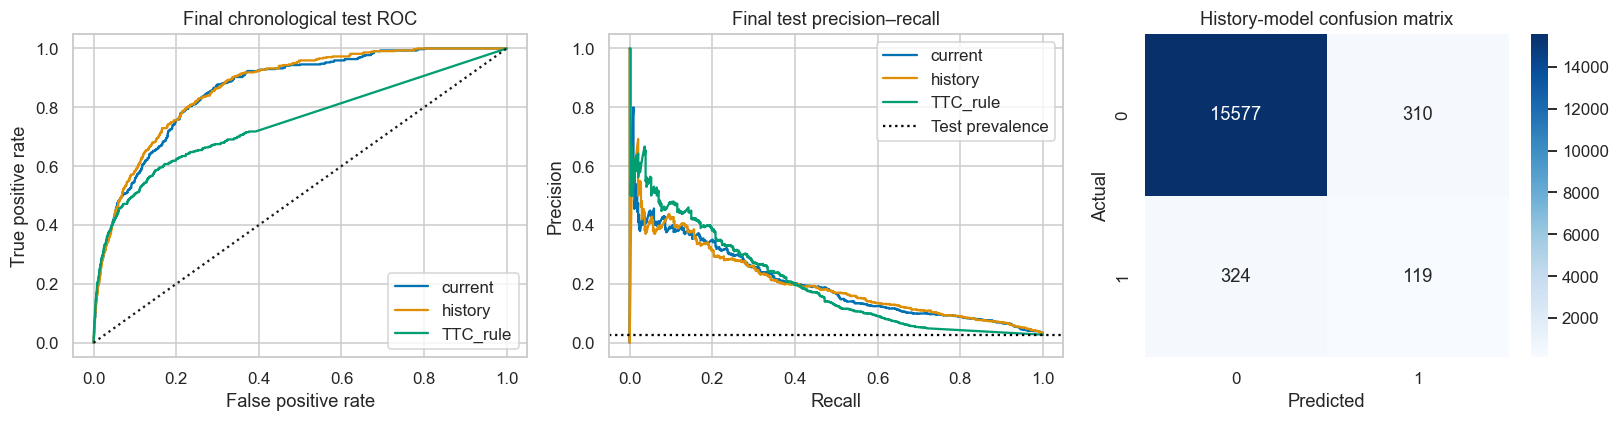

History-model test Brier: 0.2623915605789502


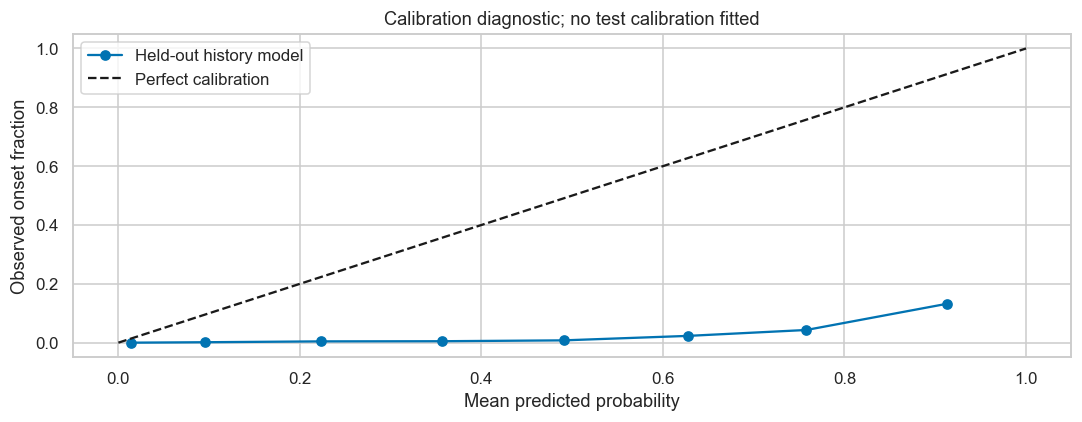

**Actual test result:** history model precision 0.277, recall 0.269, F1 0.273, ROC-AUC 0.869; false positives 310, false negatives 324. Read these alongside prevalence and the rule baseline. Reliability departures from the diagonal show why a probability should not automatically be interpreted as a real-world accident chance.

In [13]:
def classification_metrics(y, probability, decision):
    """Compute real held-out ranking and operating-point metrics."""
    tn,fp,fn,tp = confusion_matrix(y,decision,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,decision),
        precision=precision_score(y,decision,zero_division=0),
        recall=recall_score(y,decision,zero_division=0),
        f1=f1_score(y,decision,zero_division=0),
        roc_auc=roc_auc_score(y,probability),
        average_precision=average_precision_score(y,probability),
        TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp))

evaluation_rows, risk_predictions = [], {}
for partition, block in [('train',train),('validation',valid),('test',test)]:
    for name, features in [('current',current_features),('history',rich_features)]:
        probability = models[name].predict_proba(block[features])[:,1]
        decision = probability >= probability_thresholds[name]
        evaluation_rows.append(dict(partition=partition,model=name,
            **classification_metrics(block.target,probability,decision)))
        if partition == 'test': risk_predictions[name] = (probability,decision)
    decision = block.ttc.le(rule_cutoff).to_numpy()
    evaluation_rows.append(dict(partition=partition,model='TTC_rule',
        **classification_metrics(block.target,block.inverse_ttc,decision)))
    if partition == 'test': risk_predictions['TTC_rule'] = (block.inverse_ttc.to_numpy(),decision)
risk_evaluation = pd.DataFrame(evaluation_rows)
display(risk_evaluation)
test_evaluation = risk_evaluation[risk_evaluation.partition == 'test'].set_index('model')
fig, axes = plt.subplots(1,3,figsize=(15,4))
for name, (probability,decision) in risk_predictions.items():
    fpr,tpr,_ = roc_curve(test.target,probability)
    precision,recall,_ = precision_recall_curve(test.target,probability)
    axes[0].plot(fpr,tpr,label=name)
    axes[1].plot(recall,precision,label=name)
axes[0].plot([0,1],[0,1],'k:'); axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Final chronological test ROC'); axes[0].legend()
axes[1].axhline(test.target.mean(),color='black',ls=':',label='Test prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Final test precision–recall'); axes[1].legend()
sns.heatmap(confusion_matrix(test.target,risk_predictions['history'][1],labels=[0,1]),
            annot=True,fmt='d',cmap='Blues',ax=axes[2])
axes[2].set(xlabel='Predicted',ylabel='Actual',title='History-model confusion matrix')
showplot()
print('History-model test Brier:',brier_score_loss(test.target,risk_predictions['history'][0]))
fraction, mean_probability = calibration_curve(test.target,risk_predictions['history'][0],n_bins=8,strategy='quantile')
plt.plot(mean_probability,fraction,'o-',label='Held-out history model')
plt.plot([0,1],[0,1],'k--',label='Perfect calibration')
plt.xlabel('Mean predicted probability'); plt.ylabel('Observed onset fraction')
plt.title('Calibration diagnostic; no test calibration fitted'); plt.legend(); showplot()
h = test_evaluation.loc['history']
display(Markdown(f'**Actual test result:** history model precision {h.precision:.3f}, recall {h.recall:.3f}, '
    f'F1 {h.f1:.3f}, ROC-AUC {h.roc_auc:.3f}; false positives {int(h.FP)}, false negatives {int(h.FN)}. '
    'Read these alongside prevalence and the rule baseline. Reliability departures from the diagonal '
    'show why a probability should not automatically be interpreted as a real-world accident chance.'))

## 13. Original experiment — Does history improve forecasts?
Compare current-state and enriched-history Logistic Regression on the **same**
training/validation/test anchors. Both receive identical tuning opportunities,
and each threshold is chosen only on validation. A gain is empirical, not assumed.
The enriched model adds no new future information.

,precision,recall,f1,roc_auc
model,,,,
TTC_rule,0.267857,0.304740,0.285111,0.747112
current,0.256917,0.293454,0.273973,0.862152
history,0.277389,0.268623,0.272936,0.868573


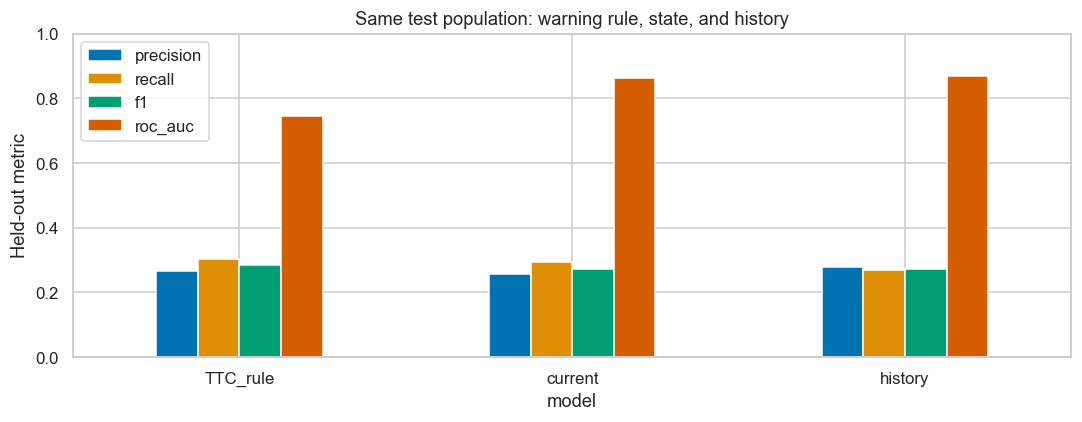

,history minus current
precision,0.020472
recall,-0.024831
f1,-0.001037
roc_auc,0.006421


**Finding → decision:** history changes F1 by -0.001, recall by -0.025, precision by +0.020, and ROC-AUC by +0.006. These actual differences support only the conclusion shown here. Do not retune after observing them, and do not assume an improvement in one metric implies an improvement in every operating objective.

In [14]:
comparison = test_evaluation.loc[['TTC_rule','current','history'],['precision','recall','f1','roc_auc']]
display(comparison)
comparison.plot.bar(rot=0,ylim=(0,1))
plt.ylabel('Held-out metric'); plt.title('Same test population: warning rule, state, and history'); showplot()
history_gain = comparison.loc['history']-comparison.loc['current']
display(history_gain.to_frame('history minus current'))
display(Markdown(f'**Finding → decision:** history changes F1 by {history_gain.f1:+.3f}, '
    f'recall by {history_gain.recall:+.3f}, precision by {history_gain.precision:+.3f}, '
    f'and ROC-AUC by {history_gain.roc_auc:+.3f}. These actual differences support only the '
    'conclusion shown here. Do not retune after observing them, and do not assume an '
    'improvement in one metric implies an improvement in every operating objective.'))

## 14. Genuine held-out encounter and Stage 1 completion gate
Select the first sufficiently long held-out encounter containing an onset (otherwise
the first sufficiently long encounter). This is a descriptive error/behavior plot,
not model selection. The vertical line marks one prediction timestamp. Grey shading
marks its future label horizon; measurements inside that region were not available
as predictors for the marked forecast. Probabilities at later anchors are separate
rolling forecasts using their own past data.

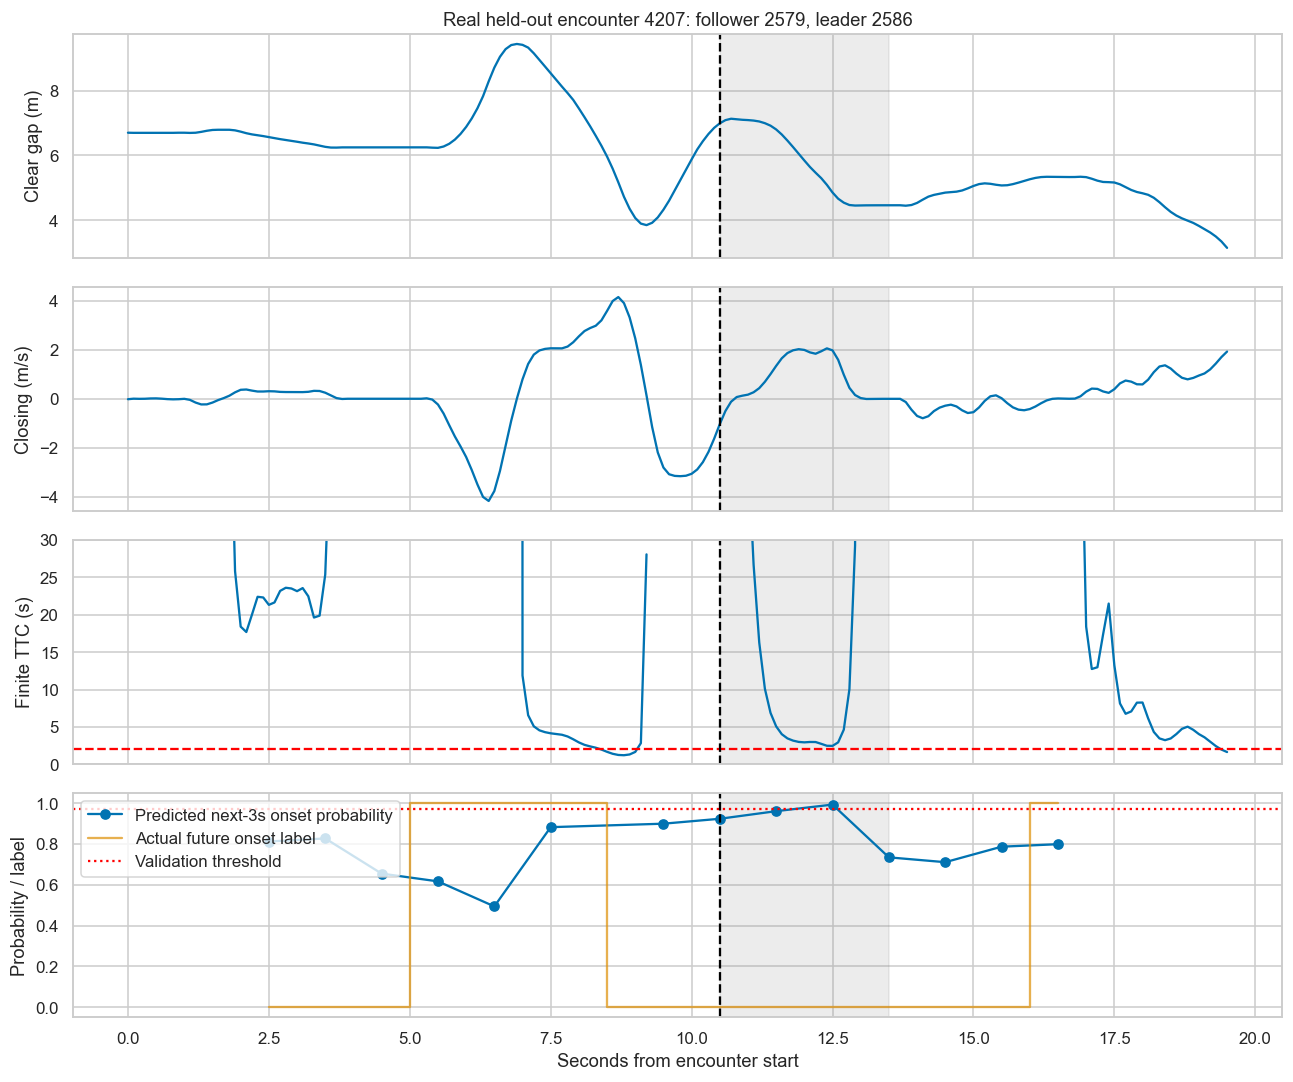

### Stage 1 completed and verified
Trained and evaluated both Logistic Regression feature groups and the TTC baseline; validated source pairing, complete horizons, past-only features and temporal separation. Test history F1 = 0.273; ROC-AUC = 0.869. The experiment predicts a project-defined surrogate among stable observed pairs, not crashes. Censoring, one recording, reconstruction noise, dependent anchors and validation reuse limit generalization. Stage 2 may now be implemented using the same cleaned trajectories.

In [15]:
encounter_counts = test.groupby('encounter').size()
eligible_encounters = encounter_counts[encounter_counts >= 5].index
assert len(eligible_encounters), 'Need a held-out encounter for the requested visualization.'
positive_ids = test[test.target.eq(1) & test.encounter.isin(eligible_encounters)].encounter.unique()
encounter_id = int(sorted(positive_ids)[0] if len(positive_ids) else eligible_encounters[0])
anchors = test[test.encounter == encounter_id].sort_values('global_time')
trace = pairs[pairs.encounter == encounter_id].sort_values('global_time')
marked = anchors.iloc[len(anchors)//2]
t0 = trace.global_time.iloc[0]
trace_seconds = (trace.global_time-t0)/1000
anchor_seconds = (anchors.global_time-t0)/1000
mark_seconds = (marked.global_time-t0)/1000
probability = models['history'].predict_proba(anchors[rich_features])[:,1]
fig, axes = plt.subplots(4,1,figsize=(12,10),sharex=True)
axes[0].plot(trace_seconds,trace.gap); axes[0].set(ylabel='Clear gap (m)',title=f'Real held-out encounter {encounter_id}: follower {int(marked.vehicle_id)}, leader {int(marked.preceding)}')
axes[1].plot(trace_seconds,trace.closing); axes[1].set(ylabel='Closing (m/s)')
axes[2].plot(trace_seconds,trace.ttc.where(np.isfinite(trace.ttc))); axes[2].axhline(2,color='red',ls='--')
axes[2].set(ylabel='Finite TTC (s)',ylim=(0, min(30,float(trace.ttc[np.isfinite(trace.ttc)].max()))))
axes[3].plot(anchor_seconds,probability,'o-',label='Predicted next-3s onset probability')
axes[3].step(anchor_seconds,anchors.target,where='mid',label='Actual future onset label',alpha=.7)
axes[3].axhline(probability_thresholds['history'],color='red',ls=':',label='Validation threshold')
axes[3].set(xlabel='Seconds from encounter start',ylabel='Probability / label',ylim=(-.05,1.05)); axes[3].legend(loc='upper left')
for ax in axes:
    ax.axvline(mark_seconds,color='black',ls='--')
    ax.axvspan(mark_seconds,mark_seconds+3,color='gray',alpha=.15)
showplot()
# The gate explicitly prevents Stage 2 from running after unresolved Stage 1 failures.
stage1_verified = bool(
    len(train)>0 and len(valid)>0 and len(test)>0 and
    np.isfinite(test_evaluation[['precision','recall','f1','roc_auc']].to_numpy()).all() and
    len(risk_predictions['history'][0]) == len(test))
assert stage1_verified
display(Markdown(f'### Stage 1 completed and verified\n'
    f'Trained and evaluated both Logistic Regression feature groups and the TTC baseline; '
    f'validated source pairing, complete horizons, past-only features and temporal separation. '
    f'Test history F1 = {h.f1:.3f}; ROC-AUC = {h.roc_auc:.3f}. '
    'The experiment predicts a project-defined surrogate among stable observed pairs, not crashes. '
    'Censoring, one recording, reconstruction noise, dependent anchors and validation reuse limit '
    'generalization. Stage 2 may now be implemented using the same cleaned trajectories.'))

# Stage 2 — One-second coordinate prediction
## 15. Research question and statistical model
Stage 1 has now been executed and verified. Reuse its cleaned trajectories, not
its risk labels. Predict **ΔX = X(t+1) − X(t)** and **ΔY = Y(t+1) − Y(t)**, then
add the predictions to current coordinates. X is lateral; Y is longitudinal,
both in metres. These continuous targets require regression rather than a binary
logistic link.

For each target, fit `statsmodels.api.GLM` with a **Gaussian family and identity
link**: E[Δcoordinate | history] = β₀ + βᵀhistory. This corresponds to a linear
conditional mean and constant-variance Gaussian working model. Residual
normality/variance are checked descriptively; robust prediction does not require
claiming that correlated trajectory errors satisfy independent Gaussian inference.

In [16]:
assert stage1_verified, 'Stage 2 requires all Stage 1 integrity and evaluation checks.'
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print('Stage 1 gate passed. Stage 2 reuses',len(clean),'clean observations; no new download.')

Stage 1 gate passed. Stage 2 reuses 1180598 clean observations; no new download.


## 16. Chronologically aligned coordinate samples
Use one second of position history (11 observations at 0.1 s) and the exact
timestamp one second ahead. Require continuous tracking within a trajectory run;
no interpolation and no bridging missing frames. A vehicle's full recording span
must belong to one chronological block, preventing the same vehicle from entering
different Stage 2 partitions. Boundary vehicles are explicitly excluded.

## 17. Interpretable movement features
**Basic:** displacement over the past second in X and Y. These are also the past
average velocity components because the observation duration is one second.

**Enriched:** add average supplied speed and acceleration over those 11 observations,
change in coordinate-derived velocity between the first/last half-second, and
standard deviation of the 10 lateral/longitudinal 0.1-second displacements.
The two components encode movement direction without an unstable angle near zero
speed. All features end at t. Future coordinates appear only in target metadata.

The constant-velocity baseline extrapolates the past one-second average velocity
for one further second. It therefore predicts ΔX/ΔY equal to past displacement;
it is not a stationary-position baseline.

,sequential_exclusion_count
off_one_second_anchor_grid,1062522
insufficient_contiguous_history,2169
missing_exact_one_second_future,2169
vehicle_crosses_split_or_embargo,20469
eligible_coordinate_samples,93269


train samples: 60399 vehicles: 1310
validation samples: 14850 vehicles: 300
test samples: 18020 vehicles: 241


Exact future coordinates, historical endpoints and held-out vehicle groups verified.


,dx_hist,dy_hist,speed_mean,acc_mean,velocity_change_x,velocity_change_y,x_step_std,y_step_std,delta_x,delta_y
count,60399.000000,60399.000000,60399.000000,60399.000000,60399.000000,60399.000000,60399.000000,60399.000000,60399.000000,60399.000000
mean,0.012866,12.757901,12.757532,0.156063,0.001585,0.087457,0.013033,0.034392,0.015085,12.933457
std,0.243432,4.036751,4.032344,0.792913,0.261401,0.698362,0.014220,0.032989,0.244220,4.111075
min,-2.390242,0.000000,0.000000,-3.413760,-2.602992,-36.693653,0.000000,0.000000,-2.390242,0.000000
25%,-0.081077,10.574426,10.568801,-0.267670,-0.050597,-0.180442,0.003354,0.013094,-0.083515,10.634929
50%,0.009144,12.684557,12.690487,0.069550,0.000000,0.015850,0.007912,0.029730,0.009754,12.953086
75%,0.101498,15.450007,15.460287,0.692173,0.064618,0.401117,0.018412,0.049401,0.104546,15.804947
max,3.765804,29.080358,28.995070,3.110068,6.730594,20.551445,0.383084,2.067726,3.765804,29.080358


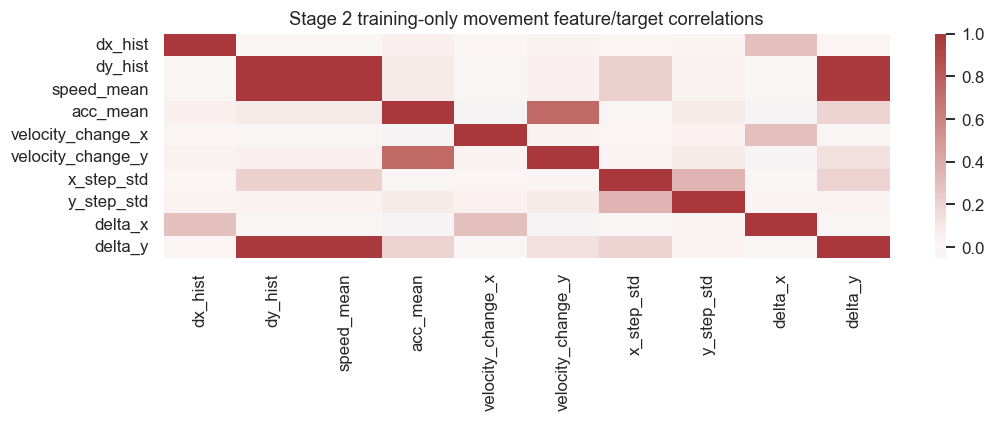

**Observation → interpretation:** displacements provide a direct kinematic reference, while acceleration and variability may account for deviations from constant velocity. **Decision:** retain the small predefined basic/enriched sets, fit preprocessing on training, and choose between them using validation position error, never test outcomes.

In [17]:
def make_coordinate_samples(vehicles):
    """Align 1-second history and 1-second future positions on real timestamps.

    Runs ensure uninterrupted 100-ms records. Whole-vehicle assignment keeps
    trajectories separate between chronological partitions. Future positions
    and displacements are targets/metadata only, never explanatory features.
    """
    table = vehicles[['recording','vehicle_id','global_time','trajectory_run',
                      'x','y','speed','acc','lane_id']].copy()
    group = table.groupby('trajectory_run',sort=False)
    table['history_start'] = group.global_time.shift(10)
    table['future_end'] = group.global_time.shift(-10)
    for coordinate in ['x','y']:
        lag10 = group[coordinate].shift(10)
        lag5 = group[coordinate].shift(5)
        table['d'+coordinate+'_hist'] = table[coordinate]-lag10
        table['velocity_change_'+coordinate] = (table[coordinate]-2*lag5+lag10)/.5
        # Ten past steps span exactly one second and exclude any future step.
        steps = group[coordinate].diff()
        table[coordinate+'_step_std'] = steps.groupby(table.trajectory_run).rolling(
            10,min_periods=10).std().reset_index(level=0,drop=True).reindex(table.index)
        table['future_'+coordinate] = group[coordinate].shift(-10)
        table['delta_'+coordinate] = table['future_'+coordinate]-table[coordinate]
    for column in ['speed','acc']:
        table[column+'_mean'] = group[column].rolling(11,min_periods=11).mean().reset_index(
            level=0,drop=True).reindex(table.index)
    bounds = vehicles.groupby('vehicle_id').global_time.agg(['min','max'])
    bounds['partition'] = assign_partition(bounds['min'],bounds['max'])
    table['partition'] = table.vehicle_id.map(bounds.partition)
    remaining = pd.Series(True,index=table.index)
    audit = {}
    for reason, bad in [
        ('off_one_second_anchor_grid',table.global_time.mod(1000).ne(0)),
        ('insufficient_contiguous_history',table.history_start.isna()),
        ('missing_exact_one_second_future',table.future_end.isna()),
        ('vehicle_crosses_split_or_embargo',table.partition.eq('excluded'))]:
        audit[reason] = int((remaining & bad).sum())
        remaining &= ~bad
    result = table.loc[remaining].copy()
    audit['eligible_coordinate_samples'] = len(result)
    assert sum(audit.values()) == len(table)
    return result, pd.Series(audit,name='sequential_exclusion_count')

coordinates, coordinate_audit = make_coordinate_samples(clean)
display(coordinate_audit.to_frame())
assert coordinates.history_start.eq(coordinates.global_time-1000).all()
assert coordinates.future_end.eq(coordinates.global_time+1000).all()
assert coordinates.groupby('vehicle_id').partition.nunique().max() == 1
basic_features = ['dx_hist','dy_hist']
enriched_features = basic_features+['speed_mean','acc_mean','velocity_change_x',
                                   'velocity_change_y','x_step_std','y_step_std']
reg_train = coordinates[coordinates.partition == 'train'].copy()
reg_valid = coordinates[coordinates.partition == 'validation'].copy()
reg_test = coordinates[coordinates.partition == 'test'].copy()
for name, block in [('train',reg_train),('validation',reg_valid),('test',reg_test)]:
    assert len(block) > 20
    assert np.isfinite(block[enriched_features+['delta_x','delta_y']]).all().all()
    assert (assign_partition(block.history_start,block.future_end) == name).all()
    print(name,'samples:',len(block),'vehicles:',block.vehicle_id.nunique())
assert not set(reg_train.vehicle_id) & set(reg_valid.vehicle_id)
assert not set(reg_train.vehicle_id) & set(reg_test.vehicle_id)
assert not set(reg_valid.vehicle_id) & set(reg_test.vehicle_id)
for _,row in coordinates.sample(min(50,len(coordinates)),random_state=SEED).iterrows():
    source = clean[(clean.vehicle_id == row.vehicle_id) & (clean.trajectory_run == row.trajectory_run)]
    past = source[source.global_time.between(row.global_time-1000,row.global_time)]
    future = source[source.global_time == row.global_time+1000]
    assert len(past) == 11 and len(future) == 1
    assert np.isclose(row.delta_x,future.x.iloc[0]-past.x.iloc[-1])
    assert np.isclose(row.delta_y,future.y.iloc[0]-past.y.iloc[-1])
    assert np.isclose(row.dx_hist,past.x.iloc[-1]-past.x.iloc[0])
print('Exact future coordinates, historical endpoints and held-out vehicle groups verified.')
display(reg_train[enriched_features+['delta_x','delta_y']].describe())
sns.heatmap(reg_train[enriched_features+['delta_x','delta_y']].corr(),cmap='vlag',center=0)
plt.title('Stage 2 training-only movement feature/target correlations')
showplot()
display(Markdown('**Observation → interpretation:** displacements provide a direct kinematic reference, '
    'while acceleration and variability may account for deviations from constant velocity. '
    '**Decision:** retain the small predefined basic/enriched sets, fit preprocessing on training, '
    'and choose between them using validation position error, never test outcomes.'))

## 18. Gaussian GLM training
Fit two Gaussian identity-link GLMs for each feature set, one for each displacement
axis. Standardization and median imputation are trained only on Stage 2 training
observations; the intercept is explicitly included. Standardized design condition
numbers audit instability. No regularization grid or unrelated algorithms are added.

Coefficients describe expected displacement changes per training standard deviation
of a feature, conditional on the others. They are **not causal effects**. Because
anchors within a vehicle are dependent, ordinary GLM inferential p-values should
not be treated as independent-sample evidence; we report coefficient estimates and
out-of-time, held-out-vehicle prediction instead.

In [18]:
regression_models, regression_preprocessors, coefficient_tables = {}, {}, []
for name, feature_list in [('basic',basic_features),('enriched',enriched_features)]:
    preprocessing = Pipeline([('imputer',SimpleImputer(strategy='median')),
                              ('scale',StandardScaler())])
    Z = preprocessing.fit_transform(reg_train[feature_list])
    design = sm.add_constant(Z,has_constant='add')
    condition_number = np.linalg.cond(design)
    print(name,'standardized design condition number:',condition_number)
    assert np.isfinite(condition_number) and condition_number < 1e8
    regression_preprocessors[name] = preprocessing
    axis_models = {}
    for axis in ['x','y']:
        fitted = sm.GLM(reg_train['delta_'+axis].to_numpy(),design,
            family=sm.families.Gaussian(link=sm.families.links.Identity())).fit()
        assert fitted.converged
        axis_models[axis] = fitted
        coefficient_tables.append(pd.DataFrame({'feature':['intercept']+feature_list,
            'coefficient':fitted.params,'model':name,'target':'delta_'+axis}))
    regression_models[name] = axis_models
coefficients_glm = pd.concat(coefficient_tables,ignore_index=True)
display(coefficients_glm)
def predict_displacement(name, block):
    """Predict future ΔX/ΔY from past-only features using frozen GLMs."""
    if name == 'constant_velocity':
        return block[['dx_hist','dy_hist']].to_numpy()
    features = basic_features if name == 'basic' else enriched_features
    design = sm.add_constant(regression_preprocessors[name].transform(block[features]),has_constant='add')
    return np.column_stack([regression_models[name][axis].predict(design) for axis in ['x','y']])

def coordinate_metrics(block, prediction):
    """Compute SI-unit forecast error; R² uses displacement, avoiding location inflation."""
    actual = block[['delta_x','delta_y']].to_numpy()
    residual = prediction-actual
    euclidean = np.linalg.norm(residual,axis=1)
    return dict(MAE_X=mean_absolute_error(actual[:,0],prediction[:,0]),
        MAE_Y=mean_absolute_error(actual[:,1],prediction[:,1]),
        RMSE_X=np.sqrt(mean_squared_error(actual[:,0],prediction[:,0])),
        RMSE_Y=np.sqrt(mean_squared_error(actual[:,1],prediction[:,1])),
        R2_delta_X=r2_score(actual[:,0],prediction[:,0]),
        R2_delta_Y=r2_score(actual[:,1],prediction[:,1]),
        mean_position_error=float(euclidean.mean()),
        median_position_error=float(np.median(euclidean)))

validation_regression = pd.DataFrame({name:coordinate_metrics(reg_valid,predict_displacement(name,reg_valid))
    for name in ['constant_velocity','basic','enriched']}).T
display(validation_regression)
selected_glm = validation_regression.loc[['basic','enriched'],'mean_position_error'].idxmin()
print('Validation-selected GLM feature group:',selected_glm)
display(Markdown('**Decision:** choose the GLM feature group by validation mean Euclidean error. '
    'Keep both groups in the final ablation and keep the constant-velocity comparison. '
    'Negative displacement R² means a model is worse than a target-mean reference for that '
    'axis; large absolute Y-coordinate range must not conceal weak movement prediction.'))

basic standardized design condition number: 1.0028279611604258
enriched standardized design condition number: 154.79538390205784


,feature,coefficient,model,target
0,intercept,0.015085,basic,delta_x
1,dx_hist,0.073866,basic,delta_x
2,dy_hist,-0.000301,basic,delta_x
3,intercept,12.933457,basic,delta_y
4,dx_hist,0.061050,basic,delta_y
5,dy_hist,4.023658,basic,delta_y
6,intercept,0.015085,enriched,delta_x
7,dx_hist,0.073686,enriched,delta_x
8,dy_hist,0.132136,enriched,delta_x
9,speed_mean,-0.130027,enriched,delta_x


,MAE_X,MAE_Y,RMSE_X,RMSE_Y,R2_delta_X,R2_delta_Y,mean_position_error,median_position_error
constant_velocity,0.187063,0.617241,0.290969,0.842206,-0.365172,0.929937,0.685589,0.569220
basic,0.151060,0.624296,0.235688,0.845602,0.104289,0.929371,0.673670,0.535009
enriched,0.140070,0.390364,0.223270,0.574504,0.196189,0.967398,0.448417,0.339245


Validation-selected GLM feature group: enriched


**Decision:** choose the GLM feature group by validation mean Euclidean error. Keep both groups in the final ablation and keep the constant-velocity comparison. Negative displacement R² means a model is worse than a target-mean reference for that axis; large absolute Y-coordinate range must not conceal weak movement prediction.

## 19. Held-out trajectory evaluation
Reconstruct predicted X/Y by adding predicted displacement to current coordinates.
Coordinate and displacement errors are identical after this reconstruction. MAE/RMSE
are reported separately in metres for each axis; Euclidean error summarizes the
two-dimensional endpoint. R² is reported for **displacement** rather than allowing
the road's large longitudinal position range to inflate apparent predictive skill.

The constant-velocity baseline and both GLM feature groups use precisely the same
test vehicles and timestamps. No test error changes model or feature selection.

,partition,model,MAE_X,MAE_Y,RMSE_X,RMSE_Y,R2_delta_X,R2_delta_Y,mean_position_error,median_position_error
0,train,constant_velocity,0.182565,0.627041,0.287997,0.862098,-0.390667,0.956025,0.693449,0.577408
1,train,basic,0.149832,0.614545,0.232779,0.841719,0.091485,0.958079,0.663976,0.524629
2,train,enriched,0.140213,0.378230,0.220561,0.580752,0.184347,0.980044,0.436497,0.329266
3,validation,constant_velocity,0.187063,0.617241,0.290969,0.842206,-0.365172,0.929937,0.685589,0.569220
4,validation,basic,0.151060,0.624296,0.235688,0.845602,0.104289,0.929371,0.673670,0.535009
5,validation,enriched,0.140070,0.390364,0.223270,0.574504,0.196189,0.967398,0.448417,0.339245
6,test,constant_velocity,0.135335,0.637789,0.246915,0.932492,-0.506336,0.960706,0.684328,0.540988
7,test,basic,0.111139,0.656878,0.195362,0.933749,0.057011,0.960600,0.689677,0.504352
8,test,enriched,0.104204,0.393214,0.186507,0.636309,0.140551,0.981703,0.433050,0.286212


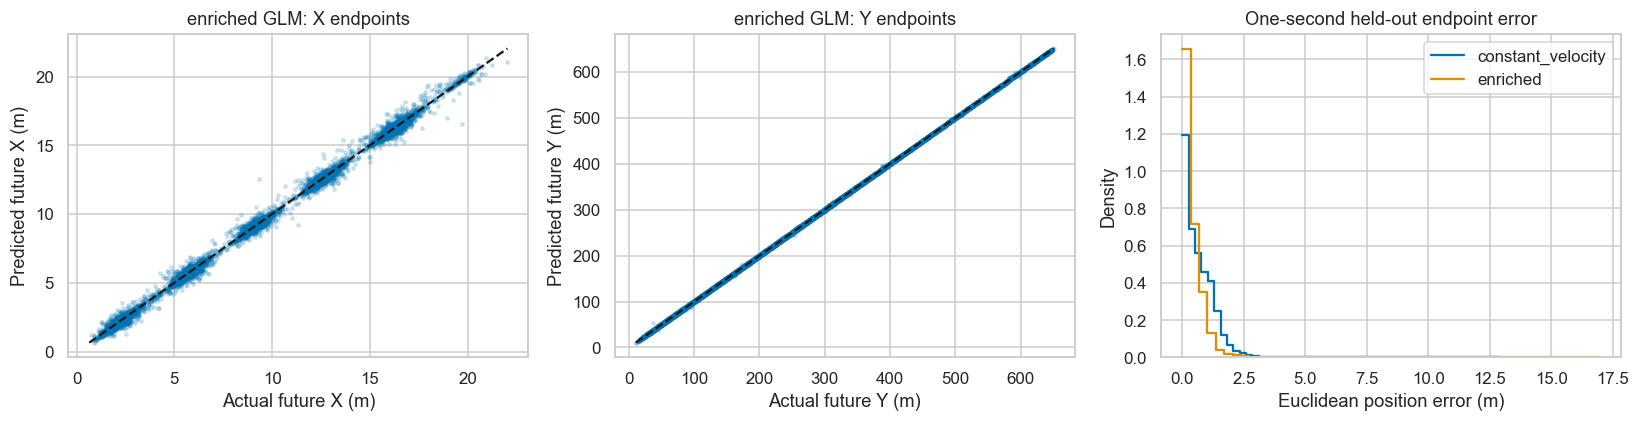

**Actual result:** validation-selected enriched GLM has mean endpoint error 0.433 m and median 0.286 m; constant velocity has mean 0.684 m. Coordinate plots can look nearly diagonal because position ranges are large, so the error distribution and displacement R² provide the more discriminating assessment.

In [19]:
regression_rows, coordinate_predictions = [], {}
for partition,block in [('train',reg_train),('validation',reg_valid),('test',reg_test)]:
    for name in ['constant_velocity','basic','enriched']:
        prediction = predict_displacement(name,block)
        regression_rows.append(dict(partition=partition,model=name,**coordinate_metrics(block,prediction)))
        if partition == 'test':
            coordinate_predictions[name] = prediction
regression_evaluation = pd.DataFrame(regression_rows)
display(regression_evaluation)
reg_test_metrics = regression_evaluation[regression_evaluation.partition == 'test'].set_index('model')
selected_prediction = coordinate_predictions[selected_glm]
predicted_xy = reg_test[['x','y']].to_numpy()+selected_prediction
actual_xy = reg_test[['future_x','future_y']].to_numpy()
assert np.allclose(predicted_xy-actual_xy,selected_prediction-reg_test[['delta_x','delta_y']].to_numpy())
fig,axes = plt.subplots(1,3,figsize=(15,4))
for i,axis in enumerate(['X','Y']):
    axes[i].scatter(actual_xy[:,i],predicted_xy[:,i],s=5,alpha=.15)
    limits = [min(actual_xy[:,i].min(),predicted_xy[:,i].min()),max(actual_xy[:,i].max(),predicted_xy[:,i].max())]
    axes[i].plot(limits,limits,'k--')
    axes[i].set(xlabel=f'Actual future {axis} (m)',ylabel=f'Predicted future {axis} (m)',title=f'{selected_glm} GLM: {axis} endpoints')
for name in ['constant_velocity',selected_glm]:
    error = np.linalg.norm(coordinate_predictions[name]-reg_test[['delta_x','delta_y']].to_numpy(),axis=1)
    sns.histplot(error,bins=50,stat='density',element='step',fill=False,label=name,ax=axes[2])
axes[2].set(xlabel='Euclidean position error (m)',title='One-second held-out endpoint error')
axes[2].legend(); showplot()
selected_score = reg_test_metrics.loc[selected_glm]
cv_score = reg_test_metrics.loc['constant_velocity']
display(Markdown(f'**Actual result:** validation-selected {selected_glm} GLM has mean '
    f'endpoint error {selected_score.mean_position_error:.3f} m and median '
    f'{selected_score.median_position_error:.3f} m; constant velocity has mean '
    f'{cv_score.mean_position_error:.3f} m. Coordinate plots can look nearly diagonal '
    'because position ranges are large, so the error distribution and displacement '
    'R² provide the more discriminating assessment.'))

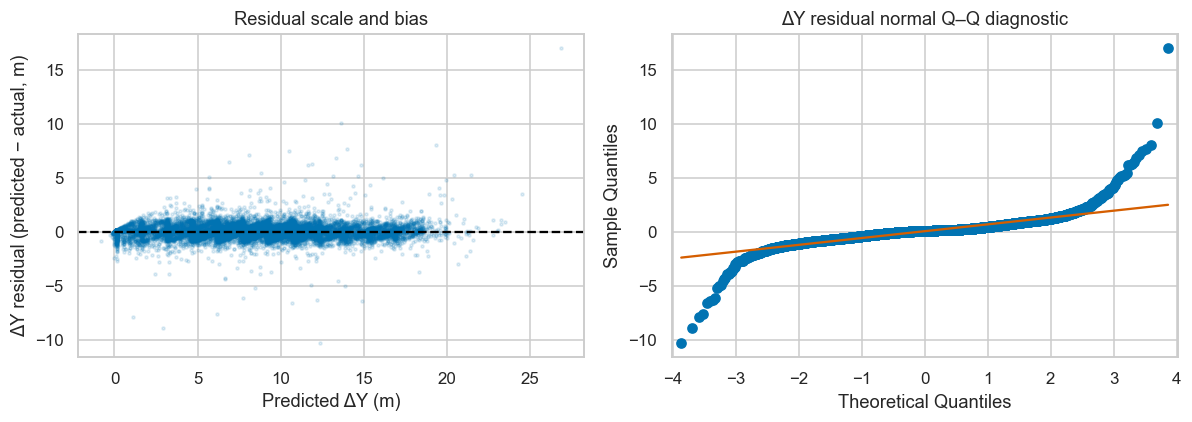

**Observation → interpretation → decision:** nonconstant scatter or departures from the Q–Q reference indicate limits of the Gaussian constant-variance working assumptions. Retain the model as a transparent forecasting baseline and report empirical errors, rather than treating conventional independent-error uncertainty as validated.

In [20]:
# Residual diagnostics assess the Gaussian working assumptions without deleting
# difficult test observations or refitting the model on their residuals.
residual = selected_prediction-reg_test[['delta_x','delta_y']].to_numpy()
fig,axes = plt.subplots(1,2,figsize=(11,4))
axes[0].scatter(selected_prediction[:,1],residual[:,1],s=4,alpha=.12)
axes[0].axhline(0,color='black',ls='--')
axes[0].set(xlabel='Predicted ΔY (m)',ylabel='ΔY residual (predicted − actual, m)',title='Residual scale and bias')
sm.qqplot(residual[:,1],line='s',ax=axes[1])
axes[1].set_title('ΔY residual normal Q–Q diagnostic')
showplot()
display(Markdown('**Observation → interpretation → decision:** nonconstant scatter or departures '
    'from the Q–Q reference indicate limits of the Gaussian constant-variance working '
    'assumptions. Retain the model as a transparent forecasting baseline and report empirical '
    'errors, rather than treating conventional independent-error uncertainty as validated.'))

## 20. Original experiment — acceleration and variability
Compare the basic displacement GLMs with the enriched history GLMs under the same
method, partitions and forecast horizon. Both have already been frozen. Lower
endpoint MAE/RMSE and Euclidean error are better; displacement R² measures a
different aspect of performance. Improvement must be demonstrated, not presumed.

,MAE_X,MAE_Y,RMSE_X,RMSE_Y,R2_delta_X,R2_delta_Y,mean_position_error,median_position_error
model,,,,,,,,
constant_velocity,0.135335,0.637789,0.246915,0.932492,-0.506336,0.960706,0.684328,0.540988
basic,0.111139,0.656878,0.195362,0.933749,0.057011,0.960600,0.689677,0.504352
enriched,0.104204,0.393214,0.186507,0.636309,0.140551,0.981703,0.433050,0.286212


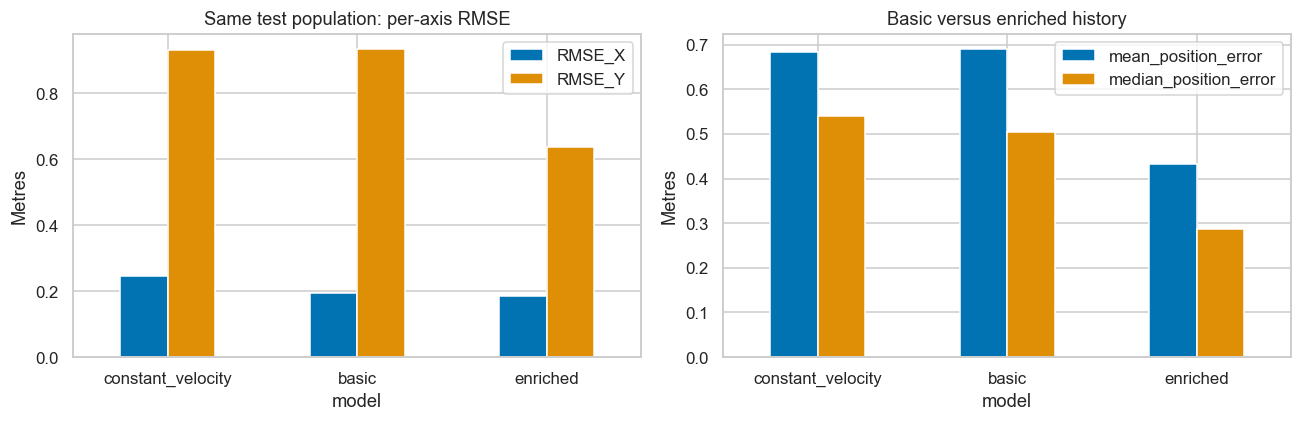

**Finding:** enrichment changes mean position error by -0.257 m (negative is improvement). The validation-selected GLM is enriched; test results are descriptive and do not replace that selection. A Stage 2 forecasting improvement does not establish a Stage 1 risk improvement.

In [21]:
display(reg_test_metrics[['MAE_X','MAE_Y','RMSE_X','RMSE_Y','R2_delta_X','R2_delta_Y','mean_position_error','median_position_error']])
fig,axes = plt.subplots(1,2,figsize=(12,4))
reg_test_metrics[['RMSE_X','RMSE_Y']].plot.bar(ax=axes[0],rot=0)
axes[0].set(ylabel='Metres',title='Same test population: per-axis RMSE')
reg_test_metrics[['mean_position_error','median_position_error']].plot.bar(ax=axes[1],rot=0)
axes[1].set(ylabel='Metres',title='Basic versus enriched history')
showplot()
enrichment_gain = reg_test_metrics.loc['basic','mean_position_error']-reg_test_metrics.loc['enriched','mean_position_error']
display(Markdown(f'**Finding:** enrichment changes mean position error by '
    f'{-enrichment_gain:+.3f} m (negative is improvement). The validation-selected '
    f'GLM is {selected_glm}; test results are descriptive and do not replace that '
    'selection. A Stage 2 forecasting improvement does not establish a Stage 1 risk improvement.'))

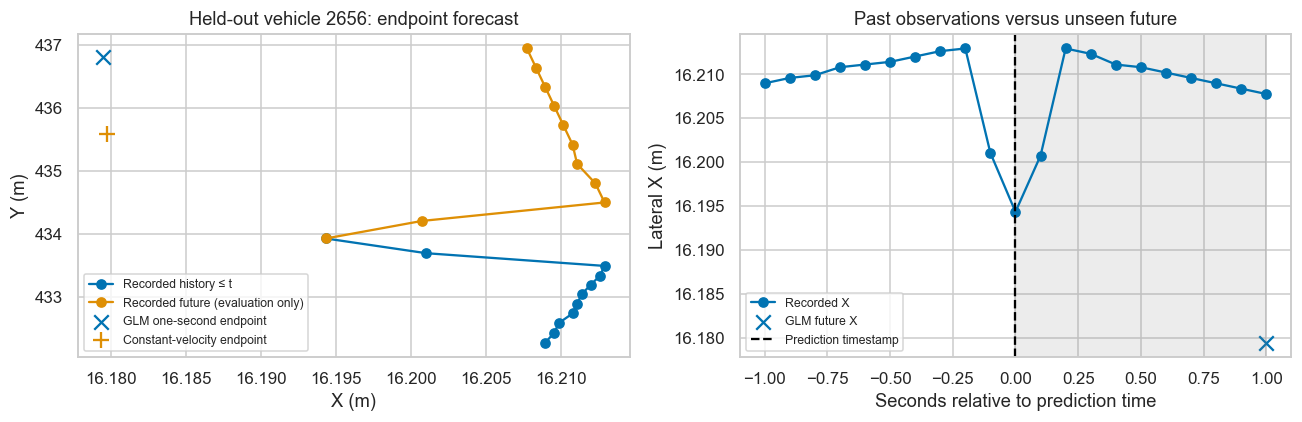

**Interpretation:** the forecast is a one-second endpoint, not a generated multi-vehicle simulation or a fitted continuous future path. Recorded future points are shown only to evaluate that endpoint. The selected held-out vehicle is not chosen to minimize error.

In [22]:
# Choose a sufficiently observed held-out vehicle for visualization, independent
# of whether its prediction looks favorable.
vehicle_counts = reg_test.groupby('vehicle_id').size()
plot_vehicle = int(vehicle_counts[vehicle_counts >= 10].sort_index().index[0])
vehicle_samples = reg_test[reg_test.vehicle_id == plot_vehicle].sort_values('global_time')
anchor = vehicle_samples.iloc[len(vehicle_samples)//2]
trajectory = clean[(clean.vehicle_id == plot_vehicle) &
    clean.global_time.between(anchor.global_time-1000,anchor.global_time+1000)].sort_values('global_time')
past = trajectory[trajectory.global_time <= anchor.global_time]
future = trajectory[trajectory.global_time >= anchor.global_time]
endpoint_delta = predict_displacement(selected_glm,anchor.to_frame().T)[0]
forecast = anchor[['x','y']].to_numpy(dtype=float)+endpoint_delta
baseline = anchor[['x','y']].to_numpy(dtype=float)+anchor[['dx_hist','dy_hist']].to_numpy(dtype=float)
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(past.x,past.y,'o-',label='Recorded history ≤ t')
axes[0].plot(future.x,future.y,'o-',label='Recorded future (evaluation only)')
axes[0].scatter([forecast[0]],[forecast[1]],marker='x',s=90,label='GLM one-second endpoint')
axes[0].scatter([baseline[0]],[baseline[1]],marker='+',s=100,label='Constant-velocity endpoint')
axes[0].set(xlabel='X (m)',ylabel='Y (m)',title=f'Held-out vehicle {plot_vehicle}: endpoint forecast'); axes[0].legend(fontsize=8)
seconds = (trajectory.global_time-anchor.global_time)/1000
axes[1].plot(seconds,trajectory.x,'o-',label='Recorded X')
axes[1].scatter([1],[forecast[0]],marker='x',s=90,label='GLM future X')
axes[1].axvline(0,color='black',ls='--',label='Prediction timestamp')
axes[1].axvspan(0,1,color='gray',alpha=.15)
axes[1].set(xlabel='Seconds relative to prediction time',ylabel='Lateral X (m)',title='Past observations versus unseen future'); axes[1].legend(fontsize=8)
showplot()
display(Markdown('**Interpretation:** the forecast is a one-second endpoint, not a generated '
    'multi-vehicle simulation or a fitted continuous future path. Recorded future points '
    'are shown only to evaluate that endpoint. The selected held-out vehicle is not '
    'chosen to minimize error.'))

## 21. Unified conclusions, limitations and reproduction
The following findings and README are populated from this actual execution.
All figures, tables and model outputs remain inside this notebook. No external
Python modules, model files, charts or result files are required.

In [23]:
stage2_verified = bool(np.isfinite(reg_test_metrics.select_dtypes(include="number").to_numpy()).all() and
    len(selected_prediction) == len(reg_test) and stage1_verified)
assert stage2_verified
stage1_summary = test_evaluation.loc[['TTC_rule','current','history'],['precision','recall','f1','roc_auc','average_precision']]
stage2_summary = reg_test_metrics[['MAE_X','MAE_Y','RMSE_X','RMSE_Y','R2_delta_X','R2_delta_Y','mean_position_error','median_position_error']]
never_warning_accuracy = float(1-test.target.mean())
train_prevalence_brier = float(np.mean((test.target-train.target.mean())**2))
display(Markdown(f"""### Findings supported by the completed execution
- **Real data:** {len(raw):,} observations and {raw.vehicle_id.nunique():,} vehicles from one complete US-101 source recording; {len(clean):,} retained after quality checks.
- **Stage 1:** {len(train):,} training, {len(valid):,} validation and {len(test):,} held-out test anchors. Test prevalence is {test.target.mean():.2%}. History-model precision {h.precision:.3f}, recall {h.recall:.3f}, F1 {h.f1:.3f}, ROC-AUC {h.roc_auc:.3f}, with {int(h.FP)} false positives and {int(h.FN)} false negatives.
- **History experiment:** F1 difference {history_gain.f1:+.3f}, AUC difference {history_gain.roc_auc:+.3f}. The TTC rule F1 is {test_evaluation.loc['TTC_rule','f1']:.3f}. Thus added history does not automatically improve the chosen warning operating point.
- **Imbalance/calibration:** never warning would achieve {never_warning_accuracy:.2%} accuracy and zero onset recall. History-model Brier score {brier_score_loss(test.target,risk_predictions['history'][0]):.3f}, compared with {train_prevalence_brier:.3f} for a constant training-prevalence forecast. The class-weighted output is poorly calibrated as an onset probability; high ranking AUC does not fix that.
- **Useful Stage 1 associations:** strongest standardized coefficient magnitudes are {', '.join(coefficients.abs().sort_values(ascending=False).head(3).index)}. Collinearity and surrogate definitions limit their interpretation.
- **Stage 2:** {len(reg_train):,} training, {len(reg_valid):,} validation, {len(reg_test):,} test endpoints with disjoint vehicle IDs. Validation selected {selected_glm} Gaussian identity-link GLMs. Test mean endpoint error {selected_score.mean_position_error:.3f} m, versus constant velocity {cv_score.mean_position_error:.3f} m.
- **Stage 2 enrichment:** enriched-minus-basic mean endpoint error {-enrichment_gain:+.3f} m. Acceleration/variability effects must be judged from this result rather than assumed.

### Limitations and next experiments
Stage 1 forecasts a **future surrogate low-TTC onset**, not an actual accident. Stage 2 forecasts coordinates; it has not been shown to improve Stage 1. Both use one recording with chronological separation, not independent days or sites. Vehicle hardware/road conditions and reconstruction artifacts limit transfer. Complete-horizon censoring excludes lane changes, disappearing pairs and short episodes, so the onset model covers stable observable following, not all traffic conflicts. Nearby anchors within a partition are dependent. Validation is reused for hyperparameter/threshold/group selection; its estimates are optimistic. Stage 1 probabilities require independent calibration; Gaussian GLM working assumptions and conventional independent-error inference are not guaranteed.

A stronger study would use additional complete recording intervals/sites, grouped temporal cross-validation, vehicle/encounter cluster uncertainty, an independent probability-calibration block and documented threshold sensitivity before external validation. No autonomous-driving deployment or real collision warning claim is made.

### References
1. USDOT/FHWA. NGSIM Vehicle Trajectories and Supporting Data, catalog 8ect-6jqj: https://data.transportation.gov/d/8ect-6jqj
2. Official US-101 metadata/data dictionary: https://data.transportation.gov/api/views/8ect-6jqj/files/ddb2c29d-2ef4-4b67-94ea-b55169229bd9?download=true&filename=1-+US+101+Metadata+Documentation.pdf
3. FHWA NGSIM program and freely available data: https://ops.fhwa.dot.gov/trafficanalysistools/ngsim.htm
4. FHWA. Surrogate Safety Assessment Model and Validation: https://www.fhwa.dot.gov/publications/research/safety/08051/ . TTC is a surrogate; the primary 2-second cutoff here is project-defined.
5. statsmodels Gaussian GLM documentation: https://www.statsmodels.org/stable/glm.html
6. scikit-learn Logistic Regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
"""))
display(stage1_summary,stage2_summary)
print('Both stages completed; all integrity and alignment assertions passed.')

### Findings supported by the completed execution
- **Real data:** 1,180,598 observations and 2,169 vehicles from one complete US-101 source recording; 1,180,598 retained after quality checks.
- **Stage 1:** 47,764 training, 12,521 validation and 16,330 held-out test anchors. Test prevalence is 2.71%. History-model precision 0.277, recall 0.269, F1 0.273, ROC-AUC 0.869, with 310 false positives and 324 false negatives.
- **History experiment:** F1 difference -0.001, AUC difference +0.006. The TTC rule F1 is 0.285. Thus added history does not automatically improve the chosen warning operating point.
- **Imbalance/calibration:** never warning would achieve 97.29% accuracy and zero onset recall. History-model Brier score 0.262, compared with 0.027 for a constant training-prevalence forecast. The class-weighted output is poorly calibrated as an onset probability; high ranking AUC does not fix that.
- **Useful Stage 1 associations:** strongest standardized coefficient magnitudes are gap, leader_mean_acc, inverse_ttc. Collinearity and surrogate definitions limit their interpretation.
- **Stage 2:** 60,399 training, 14,850 validation, 18,020 test endpoints with disjoint vehicle IDs. Validation selected enriched Gaussian identity-link GLMs. Test mean endpoint error 0.433 m, versus constant velocity 0.684 m.
- **Stage 2 enrichment:** enriched-minus-basic mean endpoint error -0.257 m. Acceleration/variability effects must be judged from this result rather than assumed.

### Limitations and next experiments
Stage 1 forecasts a **future surrogate low-TTC onset**, not an actual accident. Stage 2 forecasts coordinates; it has not been shown to improve Stage 1. Both use one recording with chronological separation, not independent days or sites. Vehicle hardware/road conditions and reconstruction artifacts limit transfer. Complete-horizon censoring excludes lane changes, disappearing pairs and short episodes, so the onset model covers stable observable following, not all traffic conflicts. Nearby anchors within a partition are dependent. Validation is reused for hyperparameter/threshold/group selection; its estimates are optimistic. Stage 1 probabilities require independent calibration; Gaussian GLM working assumptions and conventional independent-error inference are not guaranteed.

A stronger study would use additional complete recording intervals/sites, grouped temporal cross-validation, vehicle/encounter cluster uncertainty, an independent probability-calibration block and documented threshold sensitivity before external validation. No autonomous-driving deployment or real collision warning claim is made.

### References
1. USDOT/FHWA. NGSIM Vehicle Trajectories and Supporting Data, catalog 8ect-6jqj: https://data.transportation.gov/d/8ect-6jqj
2. Official US-101 metadata/data dictionary: https://data.transportation.gov/api/views/8ect-6jqj/files/ddb2c29d-2ef4-4b67-94ea-b55169229bd9?download=true&filename=1-+US+101+Metadata+Documentation.pdf
3. FHWA NGSIM program and freely available data: https://ops.fhwa.dot.gov/trafficanalysistools/ngsim.htm
4. FHWA. Surrogate Safety Assessment Model and Validation: https://www.fhwa.dot.gov/publications/research/safety/08051/ . TTC is a surrogate; the primary 2-second cutoff here is project-defined.
5. statsmodels Gaussian GLM documentation: https://www.statsmodels.org/stable/glm.html
6. scikit-learn Logistic Regression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html


,precision,recall,f1,roc_auc,average_precision
model,,,,,
TTC_rule,0.267857,0.304740,0.285111,0.747112,0.197904
current,0.256917,0.293454,0.273973,0.862152,0.200804
history,0.277389,0.268623,0.272936,0.868573,0.202429


,MAE_X,MAE_Y,RMSE_X,RMSE_Y,R2_delta_X,R2_delta_Y,mean_position_error,median_position_error
model,,,,,,,,
constant_velocity,0.135335,0.637789,0.246915,0.932492,-0.506336,0.960706,0.684328,0.540988
basic,0.111139,0.656878,0.195362,0.933749,0.057011,0.960600,0.689677,0.504352
enriched,0.104204,0.393214,0.186507,0.636309,0.140551,0.981703,0.433050,0.286212


Both stages completed; all integrity and alignment assertions passed.


In [24]:
def markdown_table(frame, digits=3):
    """Format actual result tables for README without optional table dependencies."""
    lines = ['| Model | '+' | '.join(frame.columns)+' |',
             '|---|'+'|'.join(['---:']*len(frame.columns))+'|']
    for index,row in frame.iterrows():
        lines.append('| '+str(index)+' | '+' | '.join(f'{v:.{digits}f}' for v in row)+' |')
    return '\n'.join(lines)

readme = f"""# NearMiss — Predicting Risky Vehicle Encounters and Future Vehicle Trajectories

A completed **CSE3141 Predictive Analytics mini project**, Manipal University Jaipur.
All executable project Python is inside one
[executed Jupyter Notebook](NearMiss_Complete_Predictive_Analytics.ipynb).

## Research questions

1. Can a currently noncritical same-lane following interaction enter a defined low-TTC condition within three seconds, and does recent history help predict it?
2. Can Gaussian identity-link GLMs forecast vehicle X/Y coordinates one second ahead, and do acceleration/variability features improve on basic past displacement?

Stage 1 was implemented, executed and verified before Stage 2 was added. In every
fresh sequential run, an explicit Stage 1 gate must pass before regression begins.
These are separate targets and models, sharing cleaned data.

## Real data and provenance

[USDOT NGSIM official catalog](https://data.transportation.gov/d/8ect-6jqj).
The notebook inspects the official schema and recording origins, then downloads the
**complete earliest US-101 recording**, origin {ORIGIN}, rather than an arbitrary page.
It contains **{len(raw):,} observations, {raw.vehicle_id.nunique():,} vehicles**, at 100-ms intervals.
There are {len(clean):,} cleaned observations and {len(pairs):,} geometry-validated
same-lane pair observations. Original measurements use feet, feet/s and feet/s²;
the notebook converts to SI with 0.3048.

[Official US-101 dictionary](https://data.transportation.gov/api/views/8ect-6jqj/files/ddb2c29d-2ef4-4b67-94ea-b55169229bd9?download=true&filename=1-+US+101+Metadata+Documentation.pdf).
Local_X/Y are front-center coordinates. Clear gap is leader Y minus leader length
minus follower Y. Recorded leader/follower references, lane, ordering and timestamp
must agree. Source vehicle IDs repeat across recordings, so recording identity is
explicit. [FHWA program attribution and data access](https://ops.fhwa.dot.gov/trafficanalysistools/ngsim.htm).
Raw data is not redistributed in GitHub.

## Setup and run

Tested with **Python {platform.python_version()}**. Use Python 3.13 for the pinned
scientific stack in requirements.txt.

```powershell
py -3.13 -m venv .venv
.\\.venv\\Scripts\\python -m pip install -r requirements.txt
.\\.venv\\Scripts\\python -m jupyterlab NearMiss_Complete_Predictive_Analytics.ipynb
```

Launch from this repository root, choose the environment's Python kernel, then
**Restart Kernel and Run All Cells**. All statistical logic, helpers, integrity
assertions, plots, fitted models and evaluations are in the notebook. No .py
modules, dashboard, traffic simulator or monitoring application is required.

The first full download is about 100 MB on disk and may take several minutes.
API calls use bounded pagination, retry/backoff for rate limits/server failures
and interrupted response bodies, and per-page caching in data/raw/. A SHA-256
manifest verifies subsequent local reuse (local integrity, not a publisher checksum).
The source-row count and recording-origin checks prevent silently accepting a
truncated interval. Subsequent runs reuse the cached recording.

**Local-file fallback:** export the selected complete recording from
https://data.transportation.gov/resource/8ect-6jqj.csv with
location='us-101' AND global_time-frame_id*100={ORIGIN}, requesting the columns
shown in the notebook. Save it as data/raw/us101_complete_recording.csv.
With no manifest, the notebook validates schema, exact expected row count and
recording origin before accepting it. Cached official catalog/recording metadata
or network access to those endpoints is needed to verify provenance. Failed
downloads produce a specific error; synthetic substitutes are never used.

## Shared preparation and evaluation controls

Missingness, malformed values, exact/conflicting duplicates, physical validity,
IQR/Z-score flags, continuity and leader-reference checks are reported. Statistical
extremes are investigated, not blindly removed. No interpolation bridges missing
observations. EDA includes distributions, speed/position traces, geometry,
descriptive statistics and correlations with purpose/interpretation.

One complete source recording supplies chronological 60%/20%/20% blocks with
a five-second embargo on either side of boundaries. Entire following encounters
(Stage 1) or vehicle trajectories (Stage 2) crossing blocks are excluded.
Every history-to-target support interval is checked against its block. There is
no random row split. This is one **purged predefined validation fold**, not
independent-day testing or repeated random cross-validation. Validation is reused
for selection and its estimates are optimistic. All preprocessing fits training only.

## Stage 1 — future surrogate risk classification

Primary label: any observed TTC ≤2 seconds in (t,t+3s], for a currently noncritical
pair. The cutoff is a project-defined experimental threshold; training/validation
sensitivity at 1.5/2/2.5 s is included. A complete unchanged, same-lane pair horizon
is required; missing future observations and leader/lane changes are censored,
never automatically safe. TTC uses positive closing speed; nonclosing cases have
infinite TTC and zero inverse TTC.

A two-second trailing window supplies historical summaries. Current-state features
are gap, closing speed and inverse TTC. The enriched model adds past gap trend,
relative-speed change, variability, mean acceleration and braking fraction.
Anchors are one second apart; overlapping windows stay within their partition.

Binary Logistic Regression uses a training-fit imputer/scaler Pipeline, L2
regularization, fixed balanced class weights and C∈{{0.1,1,10}} grid selection by
validation average precision. Probability thresholds maximize validation F1.
The current-TTC rule chooses its warning cutoff on validation, not test.

Training/validation/test anchors: **{len(train):,} / {len(valid):,} / {len(test):,}**.
Test onset prevalence: **{test.target.mean():.2%}**.

{markdown_table(stage1_summary)}

**Research finding:** history-minus-current F1 {history_gain.f1:+.3f}, ROC-AUC
{history_gain.roc_auc:+.3f}. History does not improve every metric; the rule's F1
is {test_evaluation.loc['TTC_rule','f1']:.3f}. History-model false positives:
{int(h.FP)}; false negatives: {int(h.FN)}. Never warning would yield
{never_warning_accuracy:.2%} accuracy with zero onset recall, illustrating why
accuracy alone is misleading.

Class-weighted probabilities are poorly calibrated: history Brier score
{brier_score_loss(test.target,risk_predictions['history'][0]):.3f}, versus
{train_prevalence_brier:.3f} for a constant training-prevalence probability.
ROC/PR curves, confusion counts and a calibration plot are included. Ranking
performance is not evidence of reliable real-world accident probabilities.

## Stage 2 — coordinate forecasting

Two **statsmodels Gaussian GLMs with identity links** predict one-second ΔX/ΔY.
Add predicted displacement to current coordinates to reconstruct X/Y. The basic
feature set uses past one-second displacement; the enriched set adds speed,
acceleration, changes in velocity and displacement variability. A constant-velocity
baseline extrapolates the same past one-second average velocity. All methods use
the same samples; no future coordinate is an input.

Training/validation/test endpoints: **{len(reg_train):,} / {len(reg_valid):,} / {len(reg_test):,}**,
with disjoint vehicle IDs. Validation selected **{selected_glm}** GLMs by mean
Euclidean endpoint error. All errors below are metres; R² is on displacement.

{markdown_table(stage2_summary)}

Enriched-minus-basic mean endpoint error: **{-enrichment_gain:+.3f} m** (negative
means improvement). Charts show actual/predicted X/Y, error distributions, residual
diagnostics, feature-group comparisons and a real held-out endpoint forecast.
Coordinate forecasting is not demonstrated to improve Stage 1 risk predictions.

## Limitations

This predicts a recorded **surrogate condition**, not confirmed accidents.
One recording, reconstruction noise, temporal drift, within-encounter dependence
and complete-horizon selection limit generalization. Excluded lane changes and
short/disappearing encounters are outside the stable-following cohort.
Stage 1 needs independent probability calibration. Stage 2 Gaussian working
assumptions are diagnosed, not presumed; ordinary independent-error inferential
p-values are not used as evidence. No causal, autonomous-driving or deployment
claim is made. Future studies need independent intervals/sites, grouped temporal
validation, cluster uncertainty and a separate calibration block.

## Submission structure

```text
NearMiss_Complete_Predictive_Analytics.ipynb   # all code, outputs and conclusions
README.md
requirements.txt
.gitignore
data/raw/.gitkeep                            # raw recordings remain local
```

All charts and results are embedded in the notebook; no external Python or model
files are needed. README and requirements are populated by its final executed cell.

## References

- USDOT/FHWA NGSIM catalog and US-101 data dictionary linked above.
- [FHWA Surrogate Safety Assessment Model](https://www.fhwa.dot.gov/publications/research/safety/08051/): TTC context; the two-second onset cutoff is this project's design choice.
- [statsmodels GLM documentation](https://www.statsmodels.org/stable/glm.html).
- [scikit-learn Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
"""
(ROOT/'README.md').write_text(readme,encoding='utf-8')
(ROOT/'requirements.txt').write_text('\n'.join(p+'=='+v for p,v in versions.items())+'\n',encoding='utf-8')
print('README.md and requirements.txt written from completed results.')
assert stage1_verified and stage2_verified
print('Final completion checks passed.')

README.md and requirements.txt written from completed results.
Final completion checks passed.
